# Ejercicios Propuestos — Modelos de Regresión
## Material de Refuerzo — Ingeniería del Conocimiento (ISO56B)
### Msc. Jaime Antonio Huaytalla Pariona — UNCP, 2026-II

---

> **Versión resuelta.** Cada ejercicio conserva su enunciado original, seguido de la solución en código y el análisis escrito.

---
## Configuración del entorno

In [1]:
import warnings
warnings.filterwarnings('ignore')

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

from sklearn import datasets
from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict, KFold, GridSearchCV)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100
SEED = 42
np.random.seed(SEED)

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def metricas(y, p):
    return {'RMSE': rmse(y, p), 'MAE': mean_absolute_error(y, p), 'R2': r2_score(y, p)}

# ---- California Housing: se usa fetch_california_housing; si no hay acceso a su servidor,
#      se reconstruye el mismo dataset (20 640 distritos) desde una copia pública en GitHub ----
URL_HOUSING = 'https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv'

def cargar_california():
    try:
        d = datasets.fetch_california_housing(as_frame=True)
        return d.data, d.target, 'sklearn.datasets.fetch_california_housing'
    except Exception:
        h = pd.read_csv(URL_HOUSING)
        X = pd.DataFrame({
            'MedInc': h['median_income'], 'HouseAge': h['housing_median_age'],
            'AveRooms': h['total_rooms'] / h['households'],
            'AveBedrms': h['total_bedrooms'] / h['households'],
            'Population': h['population'], 'AveOccup': h['population'] / h['households'],
            'Latitude': h['latitude'], 'Longitude': h['longitude']})
        X['AveBedrms'] = X['AveBedrms'].fillna(X['AveBedrms'].median())
        y = (h['median_house_value'] / 100000).rename('MedHouseVal')
        return X, y, 'copia GitHub (ageron/handson-ml)'

X_ca, y_ca, fuente_ca = cargar_california()
print('California Housing cargado desde:', fuente_ca, '| forma:', X_ca.shape, '| target en unidades de 100 000 USD')

California Housing cargado desde: copia GitHub (ageron/handson-ml) | forma: (20640, 8) | target en unidades de 100 000 USD


---
## Nivel 1: Básico (Comprensión de conceptos)

### Ejercicio 1.1 — Exploración del dataset Diabetes
**Dataset:** `sklearn.datasets.load_diabetes()` (442 muestras, 10 features, target continuo)

**Tareas:**
1. Cargar el dataset y convertirlo a DataFrame
2. Mostrar dimensiones, nombres de features y estadísticas descriptivas
3. Calcular la correlación de cada feature con el target
4. Crear scatter plots de los 4 features más correlacionados con el target
5. Crear un histograma del target y comentar su distribución
6. Responder: ¿Qué features parecen más útiles para predecir la progresión de la diabetes?

**Entregable:** Notebook con visualizaciones y respuestas escritas.

#### Solución

In [2]:
# 1-2. Carga, dimensiones, features y estadísticas descriptivas
diab = datasets.load_diabetes(as_frame=True)
df_d = diab.frame.copy()
print('Dimensiones:', df_d.shape)
print('Features:', list(diab.feature_names))
display(df_d.describe().T.round(3))

Dimensiones: (442, 11)
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,count,mean,std,min,25%,50%,75%,max
age,442.0,-0.000,0.048,-0.107,-0.037,0.005,0.038,0.111
sex,442.0,0.000,0.048,-0.045,-0.045,-0.045,0.051,0.051
bmi,442.0,-0.000,0.048,-0.090,-0.034,-0.007,0.031,0.171
bp,442.0,-0.000,0.048,-0.112,-0.037,-0.006,0.036,0.132
s1,442.0,-0.000,0.048,-0.127,-0.034,-0.004,0.028,0.154
s2,442.0,0.000,0.048,-0.116,-0.030,-0.004,0.030,0.199
s3,442.0,-0.000,0.048,-0.102,-0.035,-0.007,0.029,0.181
s4,442.0,-0.000,0.048,-0.076,-0.039,-0.003,0.034,0.185
s5,442.0,0.000,0.048,-0.126,-0.033,-0.002,0.032,0.134
s6,442.0,0.000,0.048,-0.138,-0.033,-0.001,0.028,0.136


In [3]:
# 3. Correlación de cada feature con el target
corr_t = df_d.corr()['target'].drop('target').sort_values(ascending=False)
print(corr_t.round(3).to_string())
top4 = corr_t.abs().sort_values(ascending=False).head(4).index.tolist()
print('\nLas 4 más correlacionadas (en valor absoluto):', top4)

bmi    0.586
s5     0.566
bp     0.441
s4     0.430
s6     0.382
s1     0.212
age    0.188
s2     0.174
sex    0.043
s3    -0.395

Las 4 más correlacionadas (en valor absoluto): ['bmi', 's5', 'bp', 's4']


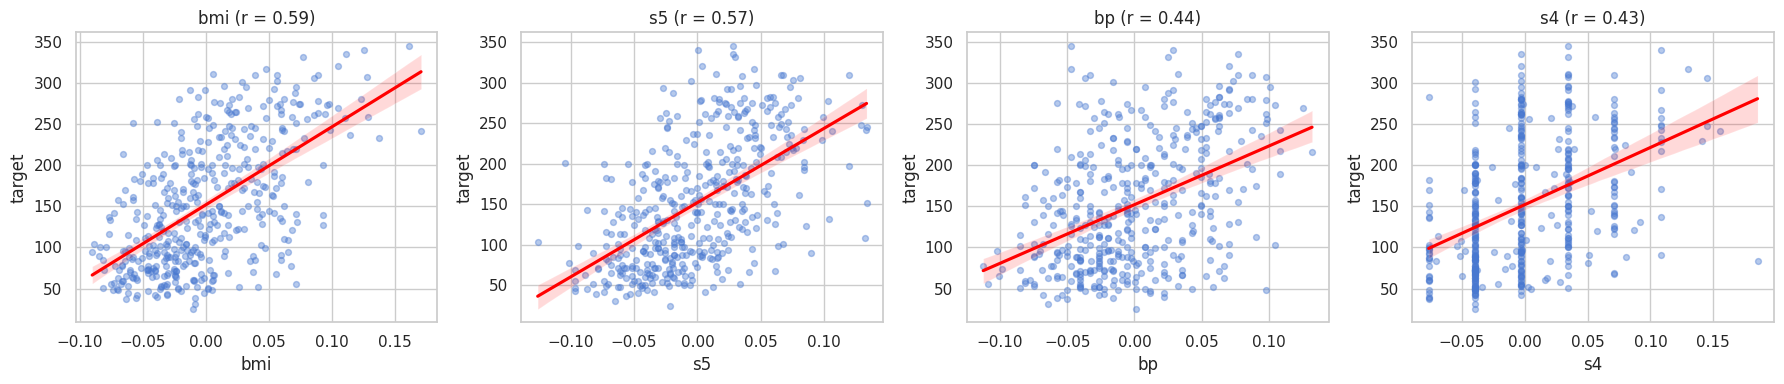

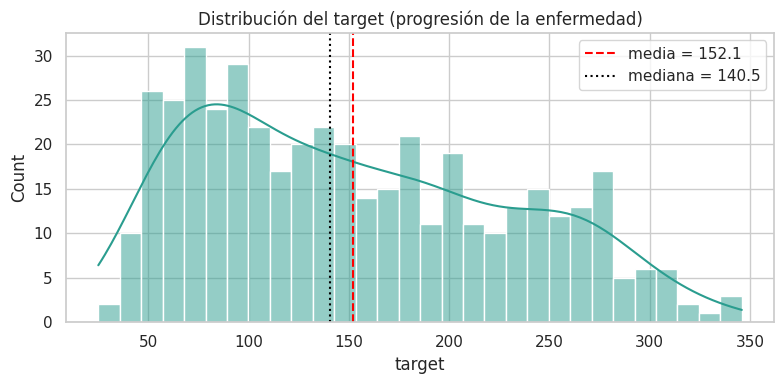

Asimetría (skewness): 0.441 | min = 25 | max = 346


In [4]:
# 4. Scatter plots de las 4 features más correlacionadas
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, top4):
    sns.regplot(data=df_d, x=c, y='target', ax=ax, scatter_kws=dict(alpha=0.4, s=18), line_kws=dict(color='red'))
    ax.set_title('%s (r = %.2f)' % (c, corr_t[c]))
plt.tight_layout(); plt.show()

# 5. Histograma del target
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df_d['target'], kde=True, bins=30, ax=ax, color='#2a9d8f')
ax.axvline(df_d['target'].mean(), color='red', linestyle='--', label='media = %.1f' % df_d['target'].mean())
ax.axvline(df_d['target'].median(), color='black', linestyle=':', label='mediana = %.1f' % df_d['target'].median())
ax.legend(); ax.set_title('Distribución del target (progresión de la enfermedad)'); plt.tight_layout(); plt.show()
print('Asimetría (skewness): %.3f | min = %.0f | max = %.0f' % (df_d['target'].skew(), df_d['target'].min(), df_d['target'].max()))

#### Respuesta
- **Dataset:** 442 pacientes, 10 features (ya estandarizadas: media 0, desviación ≈ 0.048) y un target continuo con media 152.1, mediana 140.5 y rango 25–346.
- **Distribución del target:** unimodal y ligeramente asimétrica a la derecha (skewness = 0.44, media > mediana): no es perfectamente normal pero es razonablemente "regresionable" sin transformar.
- **Correlaciones con el target:** `bmi` (0.586), `s5` (0.566), `bp` (0.441), `s4` (0.430), `s6` (0.382) y `s3` (−0.395, negativa); `sex` casi no se relaciona (0.043).

**¿Qué features parecen más útiles para predecir la progresión?** `bmi` (índice de masa corporal) y `s5` son las más informativas, seguidas de `bp` (presión arterial); `s3` también aporta, pero con relación inversa. Los scatter plots muestran tendencias crecientes claras pero con mucha dispersión, lo que anticipa que un modelo lineal no explicará más de la mitad de la variabilidad.

### Ejercicio 1.2 — Mi primera regresión lineal
**Dataset:** `sklearn.datasets.load_diabetes()`

**Tareas:**
1. Seleccionar UN solo feature (bmi) y entrenar una Regresión Lineal Simple
2. Graficar los datos (scatter) con la recta de regresión superpuesta
3. Calcular e interpretar: RMSE, MAE, R²
4. Ahora entrenar con TODOS los features y comparar las métricas
5. Responder: ¿Cuánto mejora el R² al usar todos los features? ¿Por qué tiene sentido?

**Entregable:** Gráfico de la recta, tabla comparativa y explicación.

#### Solución

Recta: y = 152.0 + 998.6 * bmi


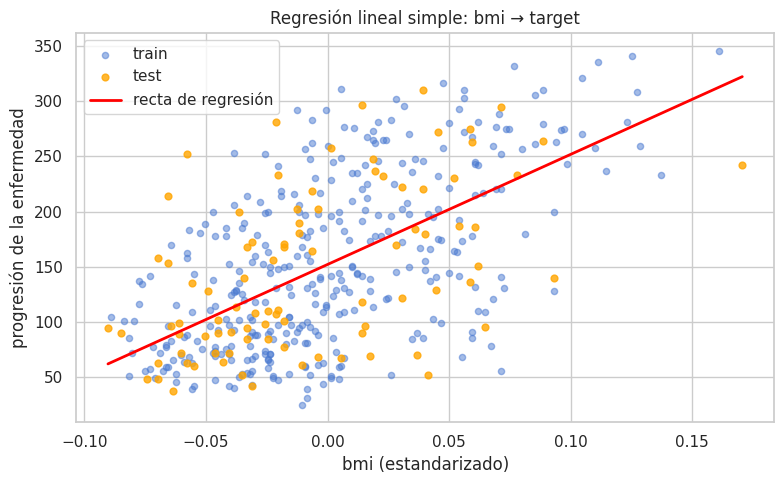

In [5]:
Xd, yd = diab.data, diab.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42)

# 1. Regresión lineal simple con UN solo feature (bmi)
lr1 = LinearRegression().fit(Xd_tr[['bmi']], yd_tr)
print('Recta: y = %.1f + %.1f * bmi' % (lr1.intercept_, lr1.coef_[0]))

# 2. Scatter + recta
xx = np.linspace(Xd['bmi'].min(), Xd['bmi'].max(), 100).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(Xd_tr['bmi'], yd_tr, alpha=0.5, label='train', s=20)
ax.scatter(Xd_te['bmi'], yd_te, alpha=0.8, label='test', s=24, color='orange')
ax.plot(xx, lr1.predict(pd.DataFrame(xx, columns=['bmi'])), color='red', lw=2, label='recta de regresión')
ax.set_xlabel('bmi (estandarizado)'); ax.set_ylabel('progresión de la enfermedad'); ax.legend()
ax.set_title('Regresión lineal simple: bmi → target'); plt.tight_layout(); plt.show()

In [6]:
# 3-4. Métricas: un feature vs todos los features
lr_all = LinearRegression().fit(Xd_tr, yd_tr)
comp = pd.DataFrame({
    'Solo bmi': metricas(yd_te, lr1.predict(Xd_te[['bmi']])),
    'Todos los features (10)': metricas(yd_te, lr_all.predict(Xd_te)),
}).T
display(comp.round(3))
print('Desviación estándar del target en test: %.1f (referencia para interpretar RMSE/MAE)' % yd_te.std())
print('Mejora de R²: %.3f -> %.3f' % (comp.loc['Solo bmi', 'R2'], comp.loc['Todos los features (10)', 'R2']))

,RMSE,MAE,R2
Solo bmi,63.732,52.260,0.233
Todos los features (10),53.853,42.794,0.453


Desviación estándar del target en test: 73.2 (referencia para interpretar RMSE/MAE)
Mejora de R²: 0.233 -> 0.453


#### Respuesta
Recta aprendida: `target = 152.0 + 998.6 · bmi` (bmi estandarizado).

| Modelo (test) | RMSE | MAE | R² |
|---|---|---|---|
| Solo `bmi` | 63.7 | 52.3 | 0.233 |
| Todos los features (10) | 53.9 | 42.8 | **0.453** |

**Interpretación:** con `bmi` solo se explica el 23 % de la varianza; el error típico (RMSE ≈ 64) es poco menor que la desviación estándar del target en test (73.2), es decir, apenas mejora a predecir siempre la media. **Con todos los features el R² sube de 0.233 a 0.453** (casi el doble) y el RMSE baja ≈ 10 puntos. Tiene sentido porque cada variable aporta información que `bmi` no tiene (presión arterial, `s5`, `s3`, etc.). Aun así queda más de la mitad de la varianza sin explicar: el modelo lineal es limitado y/o faltan variables relevantes.

### Ejercicio 1.3 — Efecto del Train/Test Split
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Entrenar una Regresión Lineal con 4 proporciones de test: 10%, 20%, 30%, 50%
2. Para cada split, reportar R² en train y en test
3. Repetir con random_state = 0, 7, 42, 99 (fijando test_size=0.2) y reportar R²
4. Calcular la desviación estándar de los R² obtenidos con diferentes random_states
5. Responder: ¿Por qué los resultados varían? ¿Qué técnica resolvería este problema?

**Entregable:** Tablas comparativas y respuesta razonada.

#### Solución

In [7]:
# 1-2. Distintos tamaños de test (random_state fijo = 42)
filas = []
for ts in [0.1, 0.2, 0.3, 0.5]:
    Xtr, Xte, ytr, yte = train_test_split(X_ca, y_ca, test_size=ts, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    filas.append({'test_size': ts, 'n_train': len(Xtr), 'n_test': len(Xte), 'R2 train': m.score(Xtr, ytr), 'R2 test': m.score(Xte, yte)})
display(pd.DataFrame(filas).round(4))

,test_size,n_train,n_test,R2 train,R2 test
0,0.1,18576,2064,0.6090,0.5810
1,0.2,16512,4128,0.6126,0.5759
2,0.3,14448,6192,0.6093,0.5958
3,0.5,10320,10320,0.6109,0.5995


In [8]:
# 3-4. Distintas semillas (test_size = 0.2)
filas = []
for rs in [0, 7, 42, 99]:
    Xtr, Xte, ytr, yte = train_test_split(X_ca, y_ca, test_size=0.2, random_state=rs)
    m = LinearRegression().fit(Xtr, ytr)
    filas.append({'random_state': rs, 'R2 train': m.score(Xtr, ytr), 'R2 test': m.score(Xte, yte)})
tabla_rs = pd.DataFrame(filas)
display(tabla_rs.round(4))
print('Desviación estándar de R² test entre semillas: %.4f' % tabla_rs['R2 test'].std())
print('Desviación estándar de R² train entre semillas: %.4f' % tabla_rs['R2 train'].std())

,random_state,R2 train,R2 test
0,0,0.6089,0.5942
1,7,0.6055,0.6075
2,42,0.6126,0.5759
3,99,0.6046,0.6124


Desviación estándar de R² test entre semillas: 0.0163
Desviación estándar de R² train entre semillas: 0.0036


In [9]:
# Técnica propuesta: validación cruzada K-fold (cada observación se usa en test exactamente una vez)
cv_r2 = cross_val_score(LinearRegression(), X_ca, y_ca, cv=KFold(10, shuffle=True, random_state=42), scoring='r2')
print('R² por fold (10-fold):', np.round(cv_r2, 3))
print('R² medio = %.4f ± %.4f' % (cv_r2.mean(), cv_r2.std()))

R² por fold (10-fold): [0.581 0.57  0.634 0.595 0.616 0.603 0.591 0.64  0.578 0.594]
R² medio = 0.6001 ± 0.0222


#### Respuesta
| test_size | R² train | R² test |
|---|---|---|
| 0.1 | 0.609 | 0.581 |
| 0.2 | 0.613 | 0.576 |
| 0.3 | 0.609 | 0.596 |
| 0.5 | 0.611 | 0.600 |

| random_state (test = 0.2) | R² test |
|---|---|
| 0 | 0.594 |
| 7 | 0.608 |
| 42 | 0.576 |
| 99 | 0.612 |

Desviación estándar del R² de test entre semillas: **0.0163** (la de train: 0.0036).

**¿Por qué varían los resultados?** Cada partición produce un conjunto de test distinto (y un train distinto), y el R² de test es una estimación con error de muestreo: entre semillas hay hasta 3.6 puntos de diferencia (0.576 con la semilla 42 frente a 0.612 con la 99). El R² de train casi no cambia porque el modelo (solo 8 coeficientes) es de varianza muy baja y siempre ve ≈ 16 000 filas; por eso tampoco depende mucho del tamaño del test.

**Técnica que lo resuelve:** la **validación cruzada K-fold**, que usa cada observación como test exactamente una vez y promedia: con 10 folds, R² = **0.600 ± 0.022**, una estimación mucho más estable que cualquier partición única.

---
## Nivel 2: Intermedio (Aplicación de algoritmos)

### Ejercicio 2.1 — Regresión Polinomial: encontrando el grado óptimo
**Dataset:** Datos sintéticos con relación no lineal

**Tareas:**
1. Generar 100 datos con: `y = 3x² - 2x + 5 + ruido`
   ```python
   np.random.seed(42)
   X = np.random.uniform(-3, 3, 100).reshape(-1, 1)
   y = 3*X.ravel()**2 - 2*X.ravel() + 5 + np.random.normal(0, 3, 100)
   ```
2. Dividir en train/test (80/20)
3. Entrenar regresiones polinomiales con grados 1 a 15
4. Graficar Train RMSE y Test RMSE vs. grado del polinomio
5. Identificar el grado óptimo y las zonas de underfitting y overfitting
6. Visualizar las curvas de los modelos con grado 1, grado óptimo y grado 15

**Entregable:** Gráficos anotados y análisis del trade-off sesgo-varianza.

#### Solución

In [10]:
np.random.seed(42)
X_p = np.random.uniform(-3, 3, 100).reshape(-1, 1)
y_p = 3 * X_p.ravel() ** 2 - 2 * X_p.ravel() + 5 + np.random.normal(0, 3, 100)

Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(X_p, y_p, test_size=0.2, random_state=42)

def pipe_poly(grado):
    # StandardScaler tras PolynomialFeatures: evita problemas numéricos con potencias altas (x^15)
    return make_pipeline(PolynomialFeatures(grado, include_bias=False), StandardScaler(), LinearRegression())

grados = range(1, 16)
rmse_tr, rmse_te, rmse_cv = [], [], []
for g in grados:
    m = pipe_poly(g).fit(Xp_tr, yp_tr)
    rmse_tr.append(rmse(yp_tr, m.predict(Xp_tr)))
    rmse_te.append(rmse(yp_te, m.predict(Xp_te)))
    cv_neg = cross_val_score(pipe_poly(g), Xp_tr, yp_tr, cv=KFold(5, shuffle=True, random_state=42),
                             scoring='neg_root_mean_squared_error')
    rmse_cv.append(-cv_neg.mean())

g_opt = list(grados)[int(np.argmin(rmse_cv))]
print('Grado óptimo según RMSE de validación cruzada (en train): %d' % g_opt)
display(pd.DataFrame({'grado': list(grados), 'RMSE train': rmse_tr, 'RMSE CV': rmse_cv, 'RMSE test': rmse_te}).round(3).set_index('grado').T)

Grado óptimo según RMSE de validación cruzada (en train): 2


grado,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
RMSE train,9.057,2.708,2.696,2.662,2.659,2.654,2.653,2.653,2.647,2.633,2.590,2.560,2.56,2.559,2.550
RMSE CV,9.482,2.743,2.785,2.861,2.879,3.022,3.192,3.310,3.357,3.602,3.247,3.335,3.15,3.954,5.691
RMSE test,8.214,2.392,2.404,2.490,2.485,2.515,2.528,2.529,2.493,2.439,2.458,2.553,2.56,2.559,2.669


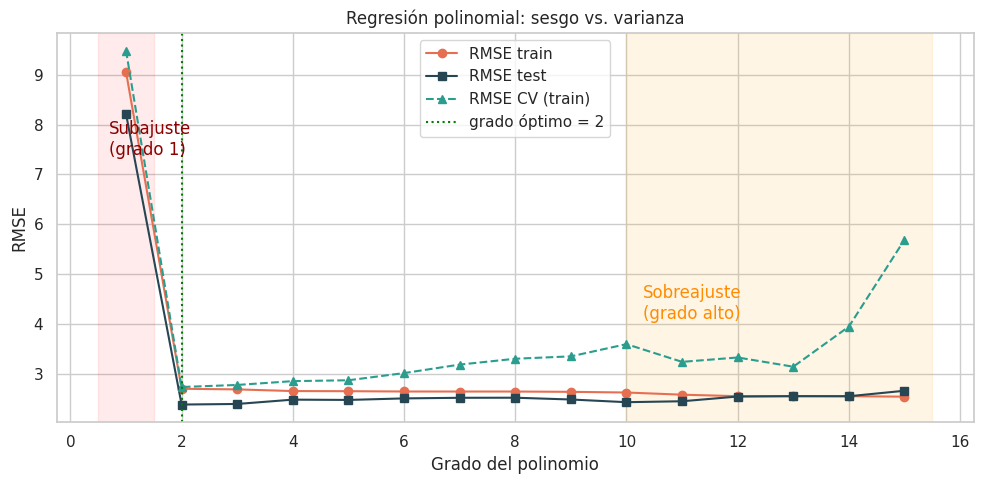

In [11]:
# 4-5. Train RMSE y Test RMSE vs. grado (con zonas de sub/sobreajuste)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(grados, rmse_tr, 'o-', label='RMSE train', color='#e76f51')
ax.plot(grados, rmse_te, 's-', label='RMSE test', color='#264653')
ax.plot(grados, rmse_cv, '^--', label='RMSE CV (train)', color='#2a9d8f')
ax.axvline(g_opt, color='green', linestyle=':', label='grado óptimo = %d' % g_opt)
ax.axvspan(0.5, 1.5, color='red', alpha=0.08); ax.text(0.7, max(rmse_te[:2]) * 0.9, 'Subajuste\n(grado 1)', color='darkred')
ax.axvspan(10, 15.5, color='orange', alpha=0.10); ax.text(10.3, max(rmse_te) * 0.5, 'Sobreajuste\n(grado alto)', color='darkorange')
ax.set_xlabel('Grado del polinomio'); ax.set_ylabel('RMSE'); ax.set_title('Regresión polinomial: sesgo vs. varianza')
ax.legend(loc='upper center'); plt.tight_layout(); plt.show()

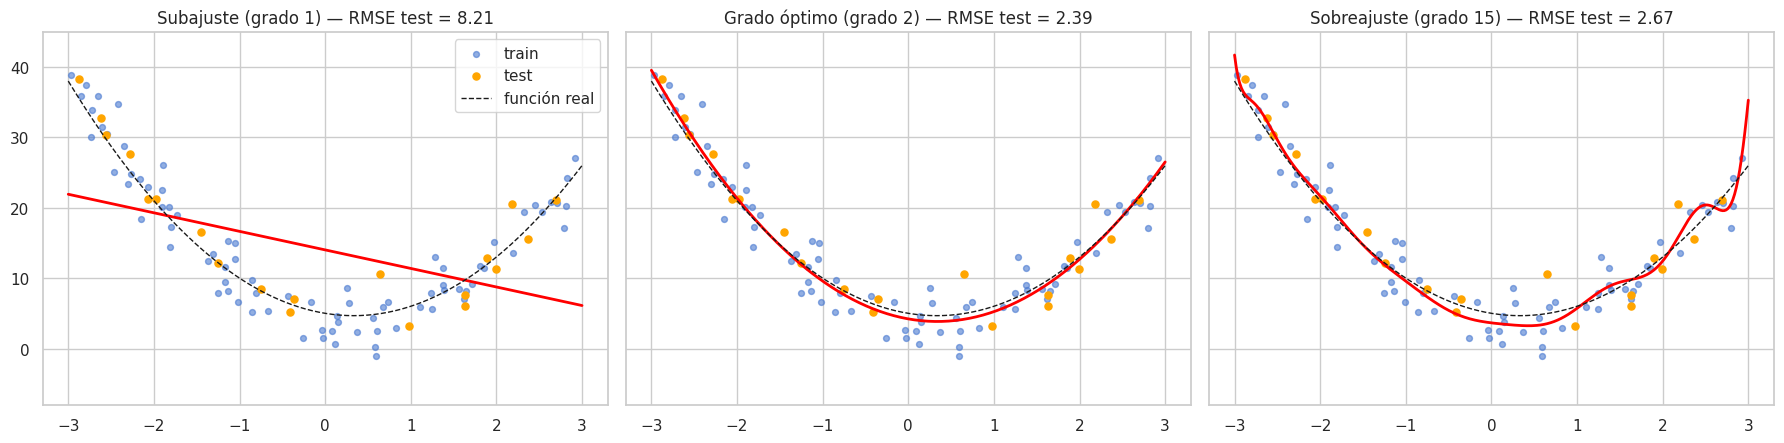

In [12]:
# 6. Curvas ajustadas: grado 1, grado óptimo y grado 15
xg = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6), sharey=True)
for ax, g, tit in zip(axes, [1, g_opt, 15], ['Subajuste', 'Grado óptimo', 'Sobreajuste']):
    m = pipe_poly(g).fit(Xp_tr, yp_tr)
    ax.scatter(Xp_tr, yp_tr, s=18, alpha=0.6, label='train')
    ax.scatter(Xp_te, yp_te, s=26, color='orange', label='test')
    ax.plot(xg, m.predict(xg), color='red', lw=2)
    ax.plot(xg, 3 * xg.ravel() ** 2 - 2 * xg.ravel() + 5, 'k--', lw=1, label='función real')
    ax.set_ylim(-8, 45)
    ax.set_title('%s (grado %d) — RMSE test = %.2f' % (tit, g, rmse(yp_te, m.predict(Xp_te))))
axes[0].legend(); plt.tight_layout(); plt.show()

#### Respuesta
| Grado | RMSE train | RMSE CV (train) | RMSE test |
|---|---|---|---|
| 1 | 9.06 | 9.48 | 8.21 |
| **2** | 2.71 | **2.74** | 2.39 |
| 6 | 2.65 | 3.02 | 2.52 |
| 15 | 2.55 | 5.69 | 2.67 |

- **Grado óptimo = 2**, que coincide con la función real (3x² − 2x + 5). El RMSE de ≈ 2.7 está cerca del ruido inyectado (σ = 3): ya no se puede bajar más sin memorizar el ruido.
- **Subajuste (grado 1):** una recta no puede representar la parábola; el error es alto tanto en train como en test (≈ 9).
- **Sobreajuste (grados altos):** el RMSE de *train* sigue bajando suavemente (2.71 → 2.55), pero el de validación cruzada sube (2.74 → 3.02 en el grado 6 → 5.69 en el grado 15) y el de test también empeora (2.39 → 2.67). Con el grado 15 la curva oscila para pasar por los puntos de entrenamiento. *Nota:* el test tiene solo 20 puntos, por eso su deterioro es más suave y ruidoso que el de la validación cruzada; esa es la razón por la que el grado óptimo se elige con CV y no con el test.
- Es el trade-off sesgo-varianza: grado bajo = alto sesgo; grado alto = alta varianza.

### Ejercicio 2.2 — Comparación Ridge vs Lasso
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Crear un pipeline con StandardScaler + Ridge y otro con StandardScaler + Lasso
2. Probar alpha = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0] para ambos modelos
3. Para cada alpha: reportar R² en test y número de coeficientes distintos de cero
4. Graficar R² vs alpha para Ridge y Lasso en el mismo gráfico
5. Graficar la evolución de los coeficientes vs alpha (un gráfico por modelo)
6. Responder: ¿Cuál es la diferencia fundamental entre Ridge y Lasso en cuanto a la selección de features?

**Entregable:** Gráficos comparativos y explicación detallada.

#### Solución

In [13]:
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_ca, y_ca, test_size=0.2, random_state=42)
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
res_rl = []
coefs = {'Ridge': [], 'Lasso': []}
for nombre, Modelo in [('Ridge', Ridge), ('Lasso', Lasso)]:
    for a in alphas:
        pipe = make_pipeline(StandardScaler(), Modelo(alpha=a, max_iter=10000) if nombre == 'Lasso' else Modelo(alpha=a))
        pipe.fit(Xa_tr, ya_tr)
        c = pipe[-1].coef_
        coefs[nombre].append(c)
        res_rl.append({'Modelo': nombre, 'alpha': a, 'R2 test': pipe.score(Xa_te, ya_te), 'Coef. ≠ 0': int((np.abs(c) > 1e-8).sum())})
tabla_rl = pd.DataFrame(res_rl)
display(tabla_rl.pivot(index='alpha', columns='Modelo', values=['R2 test', 'Coef. ≠ 0']).round(4))

R2 test         Coef. ≠ 0      
Modelo    Lasso   Ridge     Lasso Ridge
alpha                                  
0.001    0.5769  0.5759       8.0   8.0
0.010    0.5817  0.5759       7.0   8.0
0.100    0.4814  0.5759       3.0   8.0
1.000   -0.0002  0.5759       0.0   8.0
10.000  -0.0002  0.5761       0.0   8.0
100.000 -0.0002  0.5779       0.0   8.0

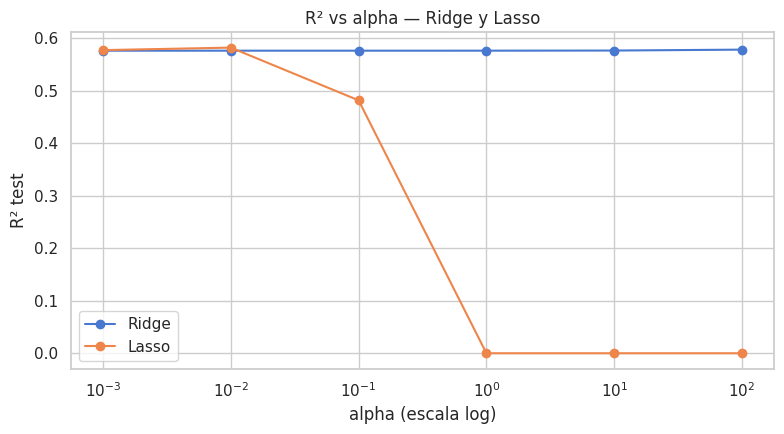

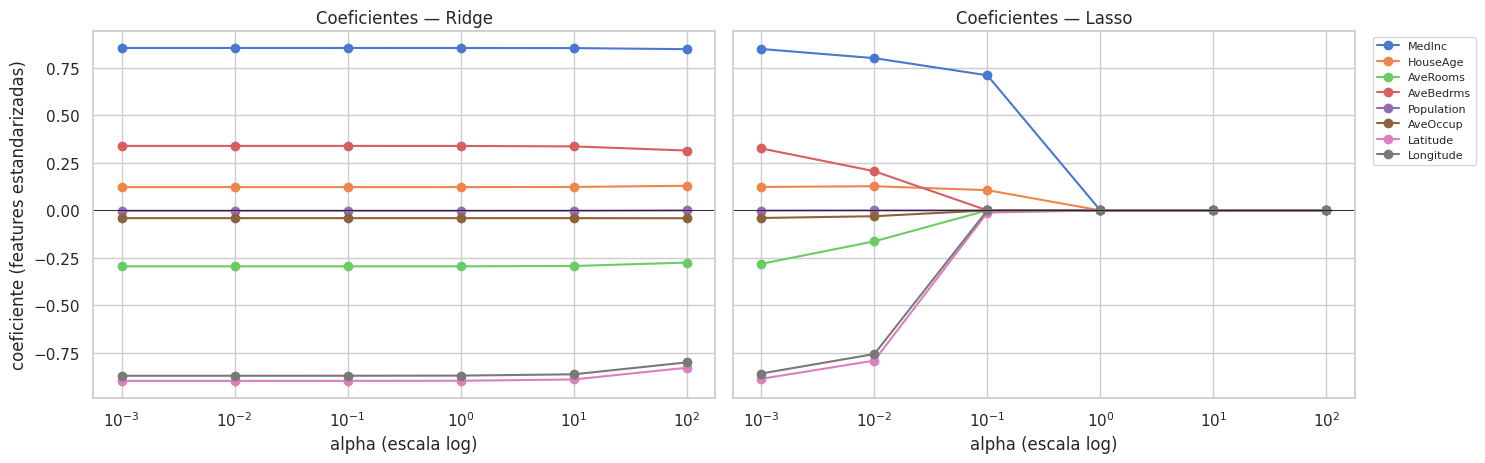

In [14]:
# 4. R² vs alpha
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre in ['Ridge', 'Lasso']:
    d = tabla_rl[tabla_rl['Modelo'] == nombre]
    ax.plot(d['alpha'], d['R2 test'], 'o-', label=nombre)
ax.set_xscale('log'); ax.set_xlabel('alpha (escala log)'); ax.set_ylabel('R² test')
ax.set_title('R² vs alpha — Ridge y Lasso'); ax.legend(); plt.tight_layout(); plt.show()

# 5. Evolución de los coeficientes vs alpha (un gráfico por modelo)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, nombre in zip(axes, ['Ridge', 'Lasso']):
    C = np.array(coefs[nombre])
    for j, col in enumerate(X_ca.columns):
        ax.plot(alphas, C[:, j], 'o-', label=col)
    ax.set_xscale('log'); ax.set_xlabel('alpha (escala log)'); ax.set_title('Coeficientes — %s' % nombre)
    ax.axhline(0, color='k', lw=0.6)
axes[0].set_ylabel('coeficiente (features estandarizadas)'); axes[1].legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

#### Respuesta
| alpha | Ridge R² | Ridge coef. ≠ 0 | Lasso R² | Lasso coef. ≠ 0 |
|---|---|---|---|---|
| 0.001 | 0.5759 | 8 | 0.5769 | 8 |
| 0.01 | 0.5759 | 8 | **0.5817** | 7 |
| 0.1 | 0.5759 | 8 | 0.4814 | 3 |
| 1 | 0.5759 | 8 | −0.0002 | 0 |
| 10 | 0.5761 | 8 | −0.0002 | 0 |
| 100 | 0.5779 | 8 | −0.0002 | 0 |

**Diferencia fundamental:** Ridge (penalización L2) **encoge** los coeficientes hacia cero pero nunca los anula: siempre conserva las 8 variables, incluso con alpha = 100. Lasso (penalización L1) puede llevar coeficientes **exactamente a cero**, por lo que hace **selección automática de variables**: con alpha = 0.01 elimina una sin perder R² (incluso mejora de 0.576 a 0.582), con alpha = 0.1 deja solo 3, y con alpha ≥ 1 elimina todas (el modelo predice siempre la media, R² ≈ 0).

Con solo 8 features y 16 500 observaciones casi no hay sobreajuste, por eso la regularización no mejora a la regresión lineal (Ridge se mantiene en ≈ 0.576): su ventaja aparece con muchas variables o con multicolinealidad. Lasso es útil cuando se quiere un modelo más simple; hay que cuidar no pasarse de alpha, porque entonces subajusta.

### Ejercicio 2.3 — Árbol de Decisión para Regresión: profundidad óptima
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Entrenar árboles de decisión con max_depth de 1 a 20
2. Registrar R² en train y test para cada profundidad
3. Graficar ambas curvas e identificar el punto de overfitting
4. Visualizar el árbol con profundidad óptima usando `plot_tree` (hasta 3 niveles)
5. Mostrar la importancia de features como gráfico de barras horizontal
6. Comparar: ¿El árbol óptimo supera a la Regresión Lineal en este dataset?

**Entregable:** Gráficos, visualización del árbol y análisis.

#### Solución

Profundidad óptima (máx. R² CV en train): 9 | R² CV = 0.6835 | R² test = 0.6827


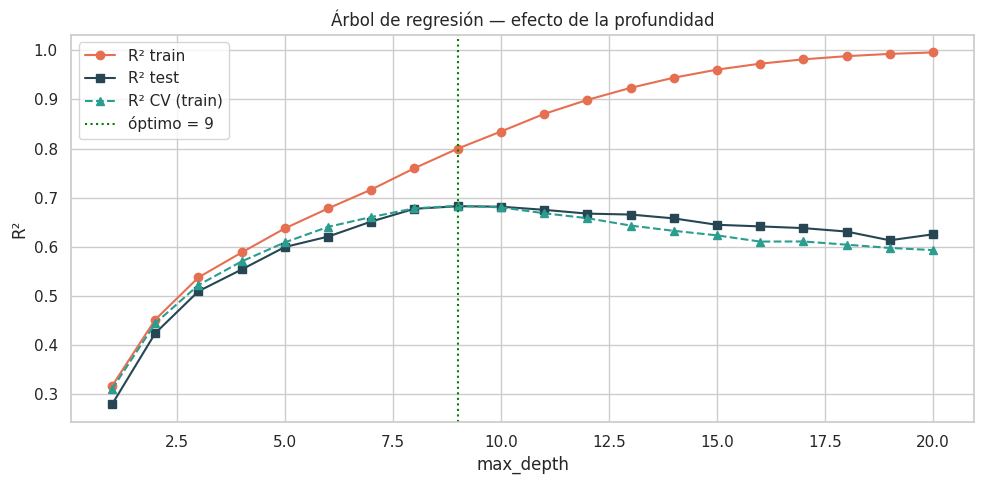

In [15]:
profs = range(1, 21)
r2_tr, r2_te, r2_cv = [], [], []
for d in profs:
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(Xa_tr, ya_tr)
    r2_tr.append(t.score(Xa_tr, ya_tr)); r2_te.append(t.score(Xa_te, ya_te))
    r2_cv.append(cross_val_score(DecisionTreeRegressor(max_depth=d, random_state=42), Xa_tr, ya_tr,
                                 cv=KFold(5, shuffle=True, random_state=42), scoring='r2').mean())
d_opt_t = list(profs)[int(np.argmax(r2_cv))]
print('Profundidad óptima (máx. R² CV en train): %d | R² CV = %.4f | R² test = %.4f' % (d_opt_t, max(r2_cv), r2_te[d_opt_t - 1]))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(profs, r2_tr, 'o-', label='R² train', color='#e76f51')
ax.plot(profs, r2_te, 's-', label='R² test', color='#264653')
ax.plot(profs, r2_cv, '^--', label='R² CV (train)', color='#2a9d8f')
ax.axvline(d_opt_t, color='green', linestyle=':', label='óptimo = %d' % d_opt_t)
ax.set_xlabel('max_depth'); ax.set_ylabel('R²'); ax.set_title('Árbol de regresión — efecto de la profundidad')
ax.legend(); plt.tight_layout(); plt.show()

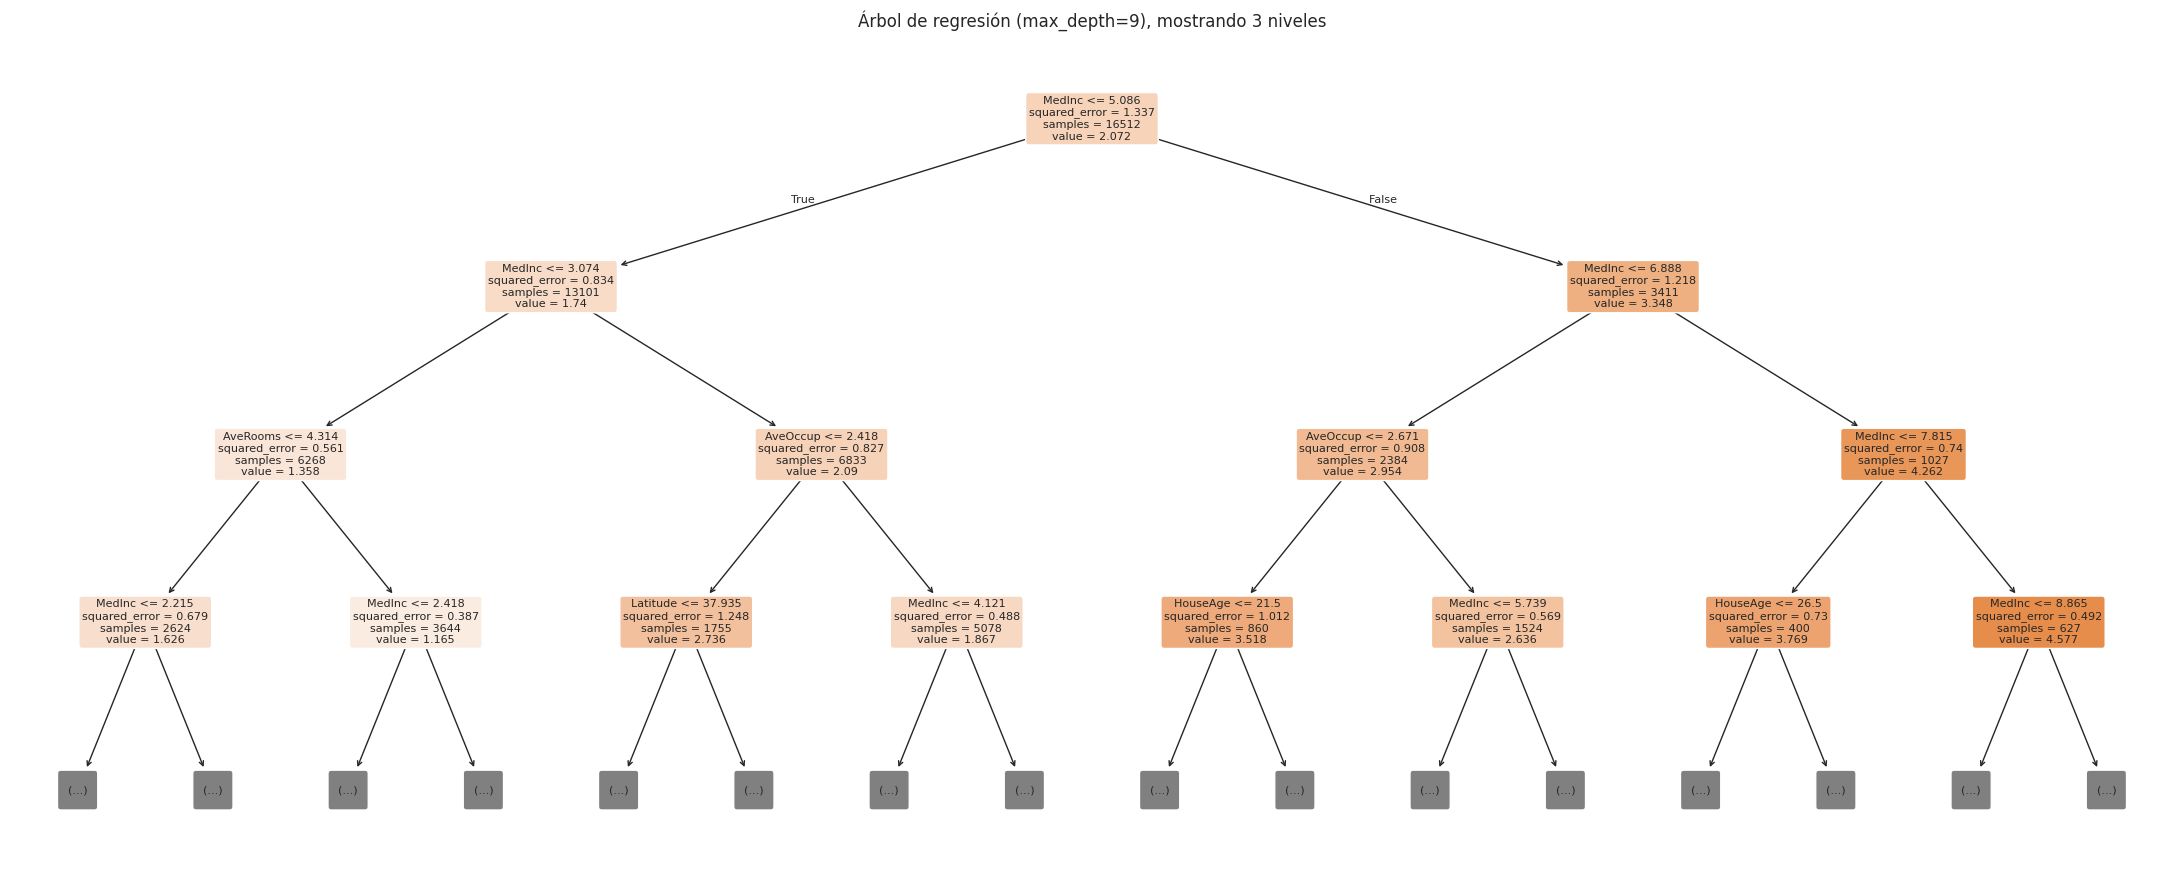

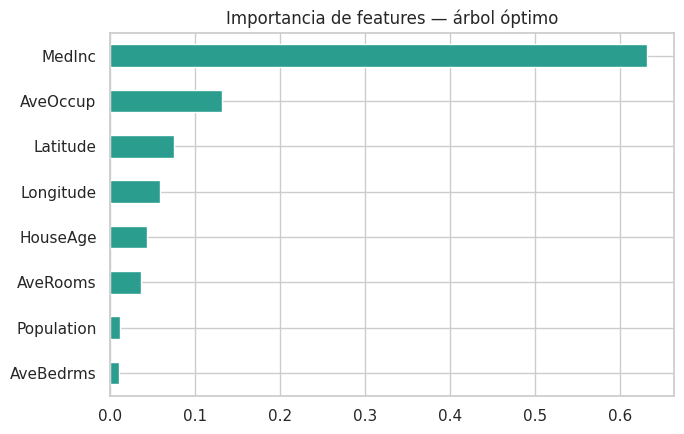

In [16]:
# 4. Árbol óptimo (se dibujan hasta 3 niveles)
arbol_r = DecisionTreeRegressor(max_depth=d_opt_t, random_state=42).fit(Xa_tr, ya_tr)
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbol_r, feature_names=list(X_ca.columns), filled=True, rounded=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title('Árbol de regresión (max_depth=%d), mostrando 3 niveles' % d_opt_t); plt.tight_layout(); plt.show()

# 5. Importancia de features
imp_t = pd.Series(arbol_r.feature_importances_, index=X_ca.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5)); imp_t.plot.barh(ax=ax, color='#2a9d8f')
ax.set_title('Importancia de features — árbol óptimo'); plt.tight_layout(); plt.show()

In [17]:
# 6. ¿Supera el árbol óptimo a la regresión lineal?
lin = LinearRegression().fit(Xa_tr, ya_tr)
comp = pd.DataFrame({
    'Regresión Lineal': metricas(ya_te, lin.predict(Xa_te)),
    'Árbol (depth=%d)' % d_opt_t: metricas(ya_te, arbol_r.predict(Xa_te)),
}).T
display(comp.round(4))

,RMSE,MAE,R2
Regresión Lineal,0.7455,0.5336,0.5759
Árbol (depth=9),0.6448,0.4363,0.6827


#### Respuesta
- **Profundidad óptima = 9** (R² CV = 0.684; R² test = 0.683).
- **Punto de overfitting:** el R² de *train* crece sin parar (0.80 en profundidad 9 → 0.87 en 11 → 0.996 en 20), mientras que el de *test* sube hasta la profundidad 9 (0.683) y luego **baja** (0.675 en 11, 0.645 en 15, 0.626 en 20). Con profundidad 1–3 hay subajuste (R² test 0.28–0.51).
- **Importancia de features (árbol de profundidad 9):** `MedInc` (0.63) domina, seguida de `AveOccup` (0.13), `Latitude` (0.08), `Longitude` (0.06) y `HouseAge` (0.04).

| Modelo (test) | RMSE | MAE | R² |
|---|---|---|---|
| Regresión Lineal | 0.7455 | 0.5336 | 0.576 |
| Árbol (depth = 9) | **0.6448** | **0.4363** | **0.683** |

**¿Supera el árbol óptimo a la regresión lineal?** Sí, con claridad (R² 0.683 vs. 0.576, RMSE −14 %): el árbol captura relaciones no lineales e interacciones (p. ej. la ubicación geográfica y el ingreso), que la regresión lineal no puede representar.

### Ejercicio 2.4 — Random Forest: número de árboles y profundidad
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Fijar max_depth=10 y probar n_estimators = [1, 5, 10, 25, 50, 100, 200, 500]
2. Graficar R² test vs número de árboles
3. Fijar n_estimators=100 y probar max_depth = [2, 4, 6, 8, 10, 12, 15, None]
4. Graficar R² test vs max_depth
5. Entrenar el modelo con la combinación óptima encontrada
6. Responder: ¿Más árboles siempre mejora el resultado? ¿Qué pasa con max_depth=None?

**Entregable:** Gráficos y análisis de hiperparámetros.

#### Solución

In [18]:
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_ca, y_ca, test_size=0.2, random_state=42)

# 1-2. max_depth = 10 fijo; variar n_estimators
n_est_lista = [1, 5, 10, 25, 50, 100, 200, 500]
r2_n, t_n = [], []
for n in n_est_lista:
    t0 = time.time()
    rf = RandomForestRegressor(n_estimators=n, max_depth=10, random_state=42, n_jobs=-1).fit(Xr_tr, yr_tr)
    r2_n.append(rf.score(Xr_te, yr_te)); t_n.append(time.time() - t0)
display(pd.DataFrame({'n_estimators': n_est_lista, 'R2 test': r2_n, 'tiempo (s)': t_n}).round(4).set_index('n_estimators').T)

n_estimators,1,5,10,25,50,100,200,500
R2 test,0.6219,0.7541,0.7618,0.7714,0.7731,0.7736,0.7746,0.7749
tiempo (s),0.0717,0.3488,0.6681,1.6725,3.2841,6.6690,13.6422,33.6971


max_depth,2,4,6,8,10,12,15,None
R2 train,0.4661,0.6276,0.7255,0.8051,0.8719,0.9198,0.9567,0.9736
R2 test,0.4380,0.5982,0.6793,0.7382,0.7736,0.7908,0.8001,0.8049
tiempo (s),1.8062,3.0260,4.4264,5.6740,6.7250,7.8713,8.9080,11.1035


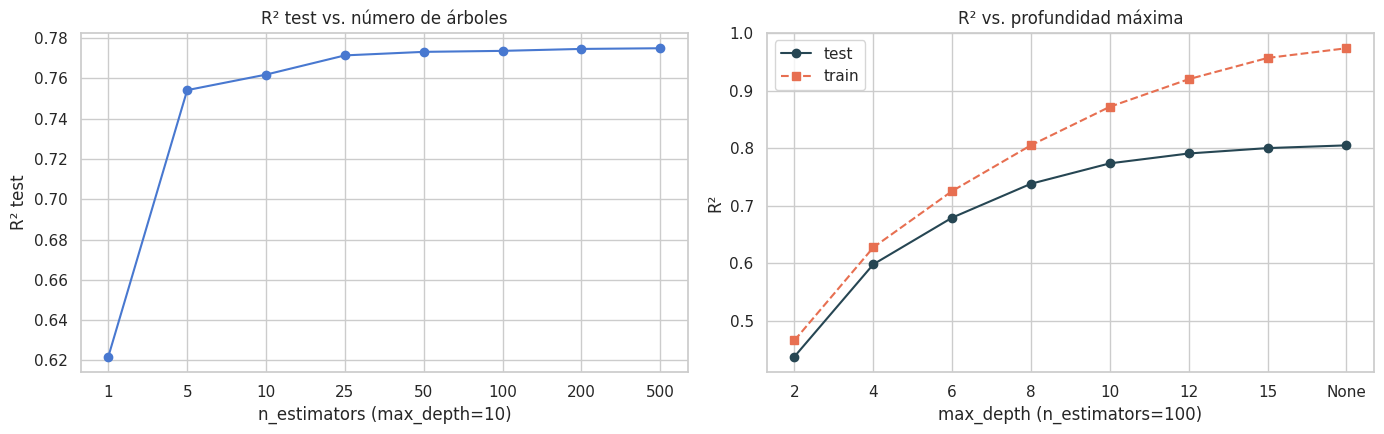

In [19]:
# 3-4. n_estimators = 100 fijo; variar max_depth
profs_rf = [2, 4, 6, 8, 10, 12, 15, None]
r2_d, r2_d_tr, t_d = [], [], []
for d in profs_rf:
    t0 = time.time()
    rf = RandomForestRegressor(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1).fit(Xr_tr, yr_tr)
    r2_d.append(rf.score(Xr_te, yr_te)); r2_d_tr.append(rf.score(Xr_tr, yr_tr)); t_d.append(time.time() - t0)
etq_d = [str(d) for d in profs_rf]
display(pd.DataFrame({'max_depth': etq_d, 'R2 train': r2_d_tr, 'R2 test': r2_d, 'tiempo (s)': t_d}).round(4).set_index('max_depth').T)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(len(n_est_lista)), r2_n, 'o-'); axes[0].set_xticks(range(len(n_est_lista))); axes[0].set_xticklabels(n_est_lista)
axes[0].set_xlabel('n_estimators (max_depth=10)'); axes[0].set_ylabel('R² test'); axes[0].set_title('R² test vs. número de árboles')
axes[1].plot(range(len(profs_rf)), r2_d, 'o-', label='test', color='#264653'); axes[1].plot(range(len(profs_rf)), r2_d_tr, 's--', label='train', color='#e76f51')
axes[1].set_xticks(range(len(profs_rf))); axes[1].set_xticklabels(etq_d)
axes[1].set_xlabel('max_depth (n_estimators=100)'); axes[1].set_ylabel('R²'); axes[1].set_title('R² vs. profundidad máxima'); axes[1].legend()
plt.tight_layout(); plt.show()

In [20]:
# 5. Modelo con la combinación óptima (mejor n_estimators del barrido 1 y mejor max_depth del barrido 2)
n_best = n_est_lista[int(np.argmax(r2_n))]
d_best = profs_rf[int(np.argmax(r2_d))]
rf_best = RandomForestRegressor(n_estimators=n_best, max_depth=d_best, random_state=42, n_jobs=-1).fit(Xr_tr, yr_tr)
print('Combinación óptima: n_estimators = %s, max_depth = %s' % (n_best, d_best))
print('Métricas test:', {k: round(v, 4) for k, v in metricas(yr_te, rf_best.predict(Xr_te)).items()})

Combinación óptima: n_estimators = 500, max_depth = None


Métricas test: {'RMSE': 0.5025, 'MAE': 0.326, 'R2': 0.8073}


#### Respuesta
| n_estimators (max_depth = 10) | 1 | 5 | 10 | 25 | 50 | 100 | 200 | 500 |
|---|---|---|---|---|---|---|---|---|
| R² test | 0.622 | 0.754 | 0.762 | 0.771 | 0.773 | 0.774 | 0.775 | 0.775 |
| Tiempo (s) | 0.1 | 0.3 | 0.7 | 1.7 | 3.3 | 6.7 | 13.6 | 33.7 |

| max_depth (100 árboles) | 2 | 4 | 6 | 8 | 10 | 12 | 15 | None |
|---|---|---|---|---|---|---|---|---|
| R² train | 0.466 | 0.628 | 0.726 | 0.805 | 0.872 | 0.920 | 0.957 | 0.974 |
| R² test | 0.438 | 0.598 | 0.679 | 0.738 | 0.774 | 0.791 | 0.800 | **0.805** |

**Combinación óptima encontrada:** `n_estimators = 500`, `max_depth = None` → R² test = **0.807**, RMSE = 0.503, MAE = 0.326.

**¿Más árboles siempre mejora?** Casi siempre no empeora, pero **la mejora se satura**: pasar de 1 a 25 árboles aporta +0.15 de R²; de 100 a 500 solo +0.001, con 5 veces más tiempo (6.7 s → 33.7 s). Más árboles reduce la varianza pero no causa sobreajuste.

**¿Qué pasa con `max_depth=None`?** En un árbol individual la profundidad máxima sobreajusta, pero en un Random Forest no: cada árbol profundo es de baja sesgo y alta varianza, y el promedio de muchos árboles decorrelacionados reduce esa varianza. Por eso el mejor R² de test (0.805) se obtiene con `max_depth=None`, a pesar de que el R² de train es 0.974 (hay brecha train-test, pero el test no empeora). El costo es mayor tiempo y memoria.

---
## Nivel 3: Avanzado (Pipelines, CV, tuning)

### Ejercicio 3.1 — Pipeline completo con Cross-Validation
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Crear pipelines con StandardScaler + cada modelo:
   - Regresión Lineal, Ridge (α=1), Lasso (α=0.01), Elastic Net (α=0.01, l1_ratio=0.5)
   - Árbol de Decisión (max_depth=8), Random Forest (100 árboles), Gradient Boosting
2. Evaluar cada pipeline con `cross_val_score` (5-fold, scoring='neg_root_mean_squared_error')
3. Crear un boxplot comparativo de los RMSE por fold para todos los modelos
4. Seleccionar el mejor modelo y evaluar en test
5. Reportar: RMSE, MAE, R² del modelo ganador en test

**Entregable:** Notebook con comparación completa y selección justificada.

#### Solución

In [21]:
Xp_tr_ca, Xp_te_ca, yp_tr_ca, yp_te_ca = train_test_split(X_ca, y_ca, test_size=0.2, random_state=42)

modelos_31 = {
    'Regresión Lineal': LinearRegression(),
    'Ridge (α=1)': Ridge(alpha=1),
    'Lasso (α=0.01)': Lasso(alpha=0.01),
    'Elastic Net (α=0.01, l1=0.5)': ElasticNet(alpha=0.01, l1_ratio=0.5),
    'Árbol (max_depth=8)': DecisionTreeRegressor(max_depth=8, random_state=42),
    'Random Forest (100)': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}
cv_kf = KFold(5, shuffle=True, random_state=42)
rmse_folds, tiempos_31 = {}, {}
for nombre, mod in modelos_31.items():
    t0 = time.time()
    s = cross_val_score(make_pipeline(StandardScaler(), mod), Xp_tr_ca, yp_tr_ca, cv=cv_kf, scoring='neg_root_mean_squared_error')
    rmse_folds[nombre] = -s; tiempos_31[nombre] = time.time() - t0
    print('%-30s RMSE CV = %.4f ± %.4f   (%.0f s)' % (nombre, -s.mean(), s.std(), tiempos_31[nombre]))

Regresión Lineal               RMSE CV = 0.7205 ± 0.0139   (0 s)
Ridge (α=1)                    RMSE CV = 0.7205 ± 0.0139   (0 s)
Lasso (α=0.01)                 RMSE CV = 0.7239 ± 0.0133   (0 s)
Elastic Net (α=0.01, l1=0.5)   RMSE CV = 0.7225 ± 0.0136   (0 s)


Árbol (max_depth=8)            RMSE CV = 0.6551 ± 0.0124   (0 s)


Random Forest (100)            RMSE CV = 0.5109 ± 0.0116   (42 s)


Gradient Boosting              RMSE CV = 0.5321 ± 0.0116   (14 s)


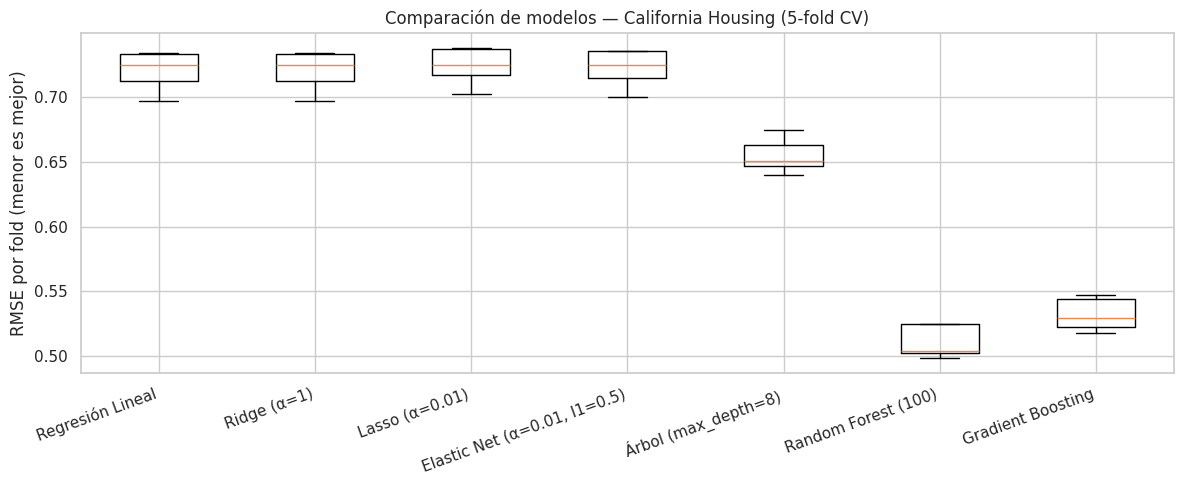

In [22]:
# 3. Boxplot comparativo
fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot(list(rmse_folds.values()), tick_labels=list(rmse_folds.keys()))
ax.set_ylabel('RMSE por fold (menor es mejor)'); ax.set_title('Comparación de modelos — California Housing (5-fold CV)')
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

In [23]:
# 4-5. Mejor modelo -> evaluar en test
mejor_31 = min(rmse_folds, key=lambda k: rmse_folds[k].mean())
final_31 = make_pipeline(StandardScaler(), modelos_31[mejor_31]).fit(Xp_tr_ca, yp_tr_ca)
m31 = metricas(yp_te_ca, final_31.predict(Xp_te_ca))
print('Mejor modelo (menor RMSE CV): %s' % mejor_31)
print('Test -> RMSE = %.4f | MAE = %.4f | R² = %.4f   (unidades: 100 000 USD)' % (m31['RMSE'], m31['MAE'], m31['R2']))
print('Es decir, error típico ≈ %.0f USD (RMSE) y %.0f USD (MAE)' % (m31['RMSE'] * 1e5, m31['MAE'] * 1e5))

Mejor modelo (menor RMSE CV): Random Forest (100)
Test -> RMSE = 0.5055 | MAE = 0.3275 | R² = 0.8050   (unidades: 100 000 USD)
Es decir, error típico ≈ 50546 USD (RMSE) y 32752 USD (MAE)


#### Respuesta
| Modelo | RMSE CV (5-fold) |
|---|---|
| Regresión Lineal | 0.7205 ± 0.0139 |
| Ridge (α = 1) | 0.7205 ± 0.0139 |
| Lasso (α = 0.01) | 0.7239 ± 0.0133 |
| Elastic Net | 0.7225 ± 0.0136 |
| Árbol (depth = 8) | 0.6551 ± 0.0124 |
| **Random Forest (100)** | **0.5109 ± 0.0116** |
| Gradient Boosting (defecto) | 0.5321 ± 0.0116 |

**Modelo seleccionado:** Random Forest (menor RMSE de validación cruzada). **Resultado en test:** RMSE = 0.5055, MAE = 0.3275, **R² = 0.805** (en dólares: error típico ≈ 50 500 USD de RMSE y ≈ 32 800 USD de MAE).

**Lectura:** los cuatro modelos lineales son prácticamente idénticos (la regularización no ayuda con 8 variables y mucho dato), y los modelos basados en árboles reducen el error un ≈ 29 % porque capturan no linealidades e interacciones. Random Forest y Gradient Boosting están cerca (la diferencia, 0.02, supera la desviación entre folds); además GB con hiperparámetros por defecto aún tiene margen de mejora (ver 3.2).

### Ejercicio 3.2 — GridSearchCV para Gradient Boosting
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Crear un Gradient Boosting Regressor
2. Definir un grid de hiperparámetros:
   - n_estimators: [100, 200, 300]
   - learning_rate: [0.01, 0.05, 0.1, 0.2]
   - max_depth: [3, 4, 5, 6]
3. Ejecutar GridSearchCV con cv=5 y scoring='neg_root_mean_squared_error'
4. Reportar los mejores hiperparámetros y el mejor RMSE (CV)
5. Evaluar el mejor modelo en test con todas las métricas (RMSE, MAE, R²)
6. Crear un heatmap de RMSE para las combinaciones de learning_rate y max_depth (fijando el mejor n_estimators)

**Entregable:** Notebook con grid search, heatmap y análisis.

#### Solución

In [24]:
# El grid pedido tiene 3 x 4 x 4 = 48 combinaciones x 5 folds = 240 entrenamientos de un GradientBoosting.
# Para que sea ejecutable en tiempo razonable, la BÚSQUEDA se hace sobre una submuestra del train (N_GRID filas)
# y luego el mejor modelo se REENTRENA con todo el train. Para usar todo el train: N_GRID = None.
N_GRID = 5000

if N_GRID is not None and N_GRID < len(Xp_tr_ca):
    idx_grid = np.random.RandomState(42).choice(len(Xp_tr_ca), N_GRID, replace=False)
    X_grid, y_grid = Xp_tr_ca.iloc[idx_grid], yp_tr_ca.iloc[idx_grid]
else:
    X_grid, y_grid = Xp_tr_ca, yp_tr_ca

param_grid_gb = {'n_estimators': [100, 200, 300], 'learning_rate': [0.01, 0.05, 0.1, 0.2], 'max_depth': [3, 4, 5, 6]}
t0 = time.time()
gs_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid_gb, cv=5,
                     scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_gb.fit(X_grid, y_grid)
print('Búsqueda terminada en %.0f s sobre %d filas' % (time.time() - t0, len(X_grid)))
print('Mejores hiperparámetros:', gs_gb.best_params_)
print('Mejor RMSE (CV, submuestra): %.4f' % (-gs_gb.best_score_))

Búsqueda terminada en 601 s sobre 5000 filas
Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}
Mejor RMSE (CV, submuestra): 0.5121


In [25]:
# 5. Reentrenar el mejor modelo con TODO el train y evaluar en test
mejor_gb = GradientBoostingRegressor(random_state=42, **gs_gb.best_params_).fit(Xp_tr_ca, yp_tr_ca)
mgb = metricas(yp_te_ca, mejor_gb.predict(Xp_te_ca))
gb_base = GradientBoostingRegressor(random_state=42).fit(Xp_tr_ca, yp_tr_ca)
comp = pd.DataFrame({'GB por defecto': metricas(yp_te_ca, gb_base.predict(Xp_te_ca)), 'GB optimizado': mgb}).T
display(comp.round(4))

,RMSE,MAE,R2
GB por defecto,0.5425,0.3719,0.7754
GB optimizado,0.4657,0.3074,0.8345


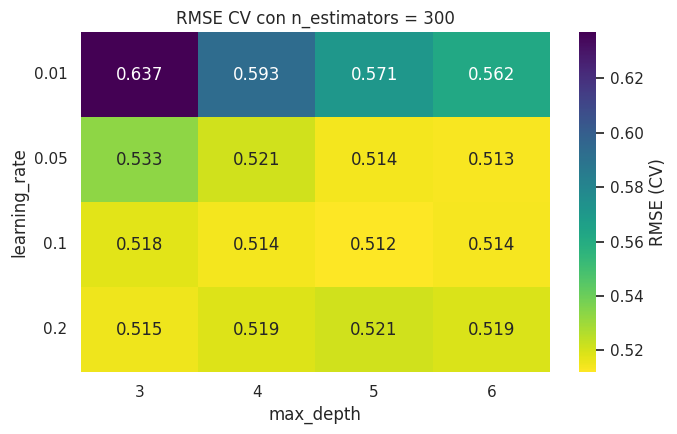

In [26]:
# 6. Heatmap de RMSE para learning_rate x max_depth (n_estimators fijo = el mejor)
res_gb = pd.DataFrame(gs_gb.cv_results_)
n_mejor = gs_gb.best_params_['n_estimators']
sub = res_gb[res_gb['param_n_estimators'] == n_mejor].copy()
sub['RMSE'] = -sub['mean_test_score']
piv = sub.pivot(index='param_learning_rate', columns='param_max_depth', values='RMSE')
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(piv, annot=True, fmt='.3f', cmap='viridis_r', ax=ax, cbar_kws={'label': 'RMSE (CV)'})
ax.set_xlabel('max_depth'); ax.set_ylabel('learning_rate'); ax.set_title('RMSE CV con n_estimators = %d' % n_mejor)
plt.yticks(rotation=0); plt.tight_layout(); plt.show()

#### Respuesta
- **Mejores hiperparámetros:** `n_estimators = 300`, `learning_rate = 0.1`, `max_depth = 5` (RMSE CV = 0.512).
- **Nota metodológica:** el grid completo son 48 combinaciones × 5 folds = 240 entrenamientos; para que fuese ejecutable (≈ 10 min en un solo núcleo) la búsqueda se hizo sobre una submuestra de 5 000 filas del train y el mejor modelo se **reentrenó con todo el train**. Poniendo `N_GRID = None` se busca sobre todo el train (más lento, resultados algo distintos).

| Test | RMSE | MAE | R² |
|---|---|---|---|
| GB por defecto | 0.5425 | 0.3719 | 0.7754 |
| **GB optimizado** | **0.4657** | **0.3074** | **0.8345** |

El ajuste reduce el RMSE un 14 % y supera también al Random Forest de 3.1 (0.5055).

**Lectura del heatmap (n_estimators = 300):** con `learning_rate = 0.01` el modelo aprende demasiado lento para 300 árboles (RMSE 0.56–0.64, subajuste); entre 0.05 y 0.2 la superficie es casi plana (0.512–0.521), con el mínimo en `learning_rate = 0.1`, `max_depth = 5`. Se ve la interacción entre ambos: con tasa alta (0.2) conviene que los árboles sean poco profundos (mejor en 3), y con tasa baja, árboles más profundos.

### Ejercicio 3.3 — Análisis de residuos completo
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Entrenar el mejor modelo encontrado en el ejercicio 3.2
2. Generar las predicciones en test
3. Crear 4 gráficos de residuos:
   a. Predicción vs Valor Real (con línea diagonal)
   b. Residuos vs Predicción (buscar patrones)
   c. Histograma de residuos (verificar normalidad)
   d. Q-Q plot de residuos
4. Identificar las 10 predicciones con mayor error absoluto
5. Analizar: ¿Hay algún patrón en los errores más grandes? ¿Qué los causa?
6. Responder: ¿Los residuos sugieren que el modelo es adecuado o hay problemas sistemáticos?

**Entregable:** Los 4 gráficos, análisis de errores grandes y conclusión.

#### Solución

In [27]:
# 1-2. Mejor modelo de 3.2 y predicciones en test
y_pred_gb = mejor_gb.predict(Xp_te_ca)
res = np.asarray(yp_te_ca) - y_pred_gb
df_res = Xp_te_ca.copy()
df_res['real'] = np.asarray(yp_te_ca); df_res['pred'] = y_pred_gb; df_res['residuo'] = res; df_res['abs_err'] = np.abs(res)
print('Residuo medio: %.4f | desviación estándar: %.4f | asimetría: %.3f | curtosis (exceso): %.3f' %
      (res.mean(), res.std(), stats.skew(res), stats.kurtosis(res)))

Residuo medio: -0.0091 | desviación estándar: 0.4656 | asimetría: 0.753 | curtosis (exceso): 6.675


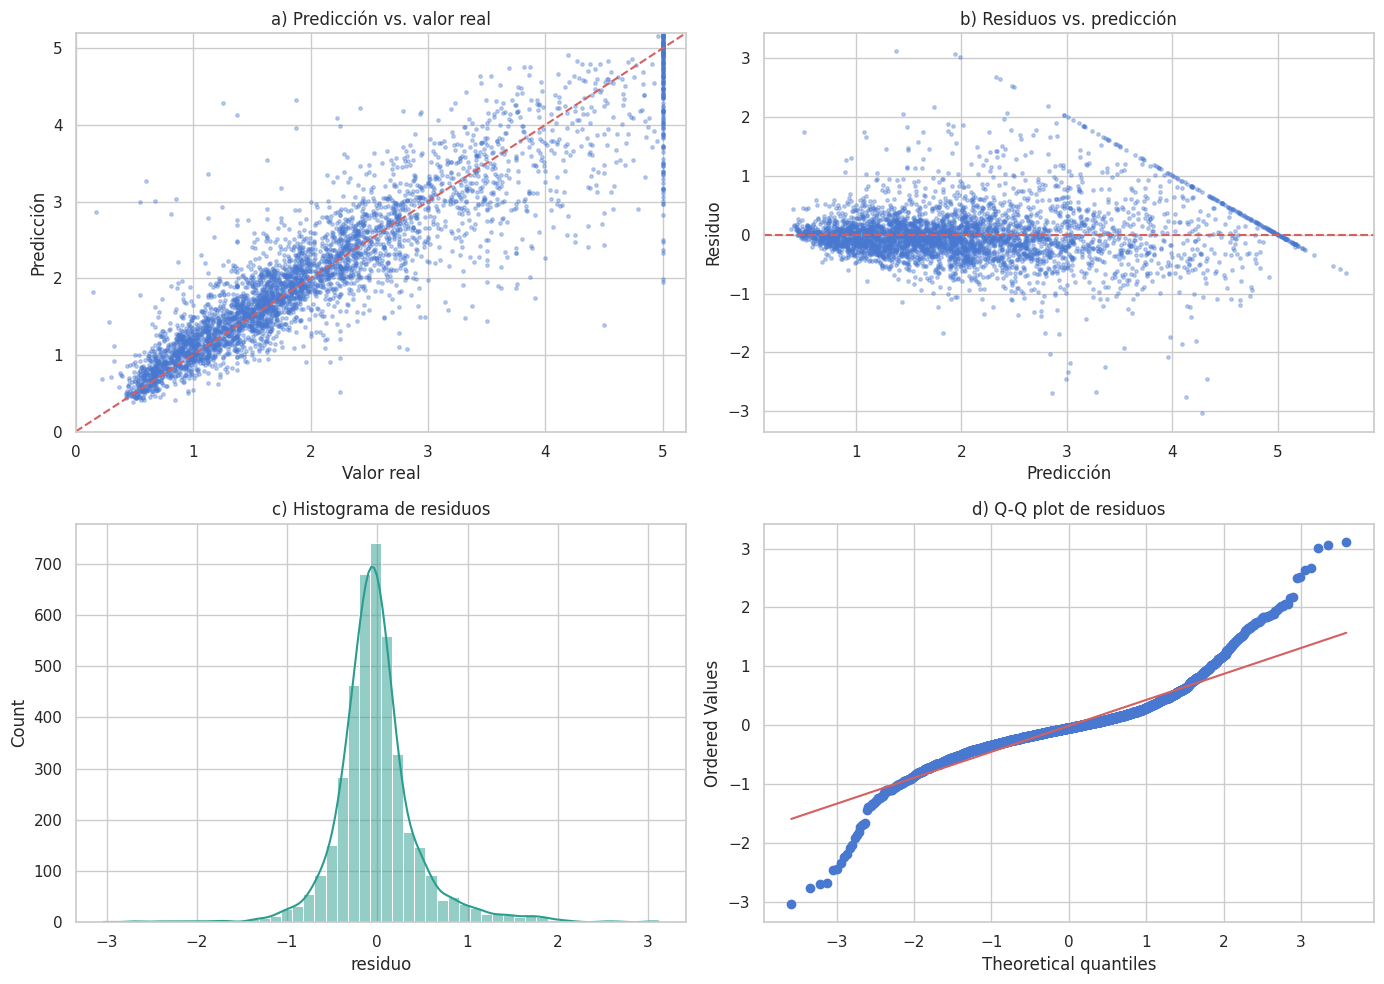

In [28]:
# 3. Los 4 gráficos de residuos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
ax = axes[0, 0]
ax.scatter(df_res['real'], df_res['pred'], s=6, alpha=0.35)
lim = [0, 5.2]; ax.plot(lim, lim, 'r--'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Valor real'); ax.set_ylabel('Predicción'); ax.set_title('a) Predicción vs. valor real')
ax = axes[0, 1]
ax.scatter(df_res['pred'], df_res['residuo'], s=6, alpha=0.35); ax.axhline(0, color='r', ls='--')
ax.set_xlabel('Predicción'); ax.set_ylabel('Residuo'); ax.set_title('b) Residuos vs. predicción')
ax = axes[1, 0]
sns.histplot(df_res['residuo'], kde=True, bins=50, ax=ax, color='#2a9d8f'); ax.set_title('c) Histograma de residuos')
ax = axes[1, 1]
stats.probplot(df_res['residuo'], dist='norm', plot=ax); ax.set_title('d) Q-Q plot de residuos')
plt.tight_layout(); plt.show()

In [29]:
# 4. Las 10 predicciones con mayor error absoluto
top10 = df_res.sort_values('abs_err', ascending=False).head(10)
display(top10[['real', 'pred', 'residuo', 'MedInc', 'HouseAge', 'AveRooms', 'AveOccup', 'Latitude', 'Longitude']].round(3))

# 5. Análisis de patrones en los errores grandes
tope = df_res['real'].max()
grandes = df_res.nlargest(int(0.02 * len(df_res)), 'abs_err')       # el 2 % con mayor error
print('Valor máximo del target en test: %.5f' % tope)
print('Entre el 2%% de mayores errores (%d casos): %.0f%% tienen target "tope" (≥ 4.99) y %.0f%% fueron SUBESTIMADOS (residuo > 0)' %
      (len(grandes), 100 * (grandes['real'] >= 4.99).mean(), 100 * (grandes['residuo'] > 0).mean()))
print('Proporción de casos con target tope en todo el test: %.1f%%' % (100 * (df_res['real'] >= 4.99).mean()))
print('\nRMSE por tramo del valor real:')
tramos = pd.cut(df_res['real'], [0, 1, 2, 3, 4, 5.1])
print(df_res.groupby(tramos, observed=True)['residuo'].agg(['count', 'mean', lambda s: np.sqrt((s ** 2).mean())]).rename(columns={'mean': 'sesgo medio', '<lambda_0>': 'RMSE'}).round(3).to_string())

,real,pred,residuo,MedInc,HouseAge,AveRooms,AveOccup,Latitude,Longitude
19542,4.500,1.384,3.116,1.768,39.0,5.000,2.444,37.63,-120.92
10574,5.000,1.944,3.056,1.966,6.0,4.795,2.841,33.72,-117.70
20349,1.250,4.283,-3.033,7.300,32.0,5.724,2.172,34.17,-119.08
12389,5.000,1.992,3.008,3.773,24.0,10.954,1.996,33.75,-116.43
18506,1.375,4.126,-2.751,2.625,16.0,6.400,7.200,37.00,-122.00
5887,0.175,2.863,-2.688,2.367,39.0,3.572,1.877,34.15,-118.33
12069,5.000,2.326,2.674,4.239,6.0,7.723,3.508,33.83,-117.55
59,0.600,3.274,-2.674,2.562,2.0,2.772,1.649,37.82,-122.29
20325,5.000,2.368,2.632,4.583,21.0,7.278,3.384,34.28,-119.04
6688,5.000,2.476,2.524,0.500,28.0,7.677,4.581,34.15,-118.08


Valor máximo del target en test: 5.00001
Entre el 2% de mayores errores (82 casos): 35% tienen target "tope" (≥ 4.99) y 78% fueron SUBESTIMADOS (residuo > 0)
Proporción de casos con target tope en todo el test: 4.5%

RMSE por tramo del valor real:
            count  sesgo medio   RMSE
real                                 
(0.0, 1.0]    739       -0.165  0.348
(1.0, 2.0]   1682       -0.104  0.346
(2.0, 3.0]    956        0.006  0.431
(3.0, 4.0]    412        0.162  0.623
(4.0, 5.1]    339        0.551  0.886


#### Respuesta
Estadísticos de los residuos (test): media = **−0.009** (≈ 0), desviación = 0.466, asimetría = 0.75 y curtosis en exceso = **6.7** (colas muy pesadas).

**Hallazgos:**
1. **No hay sesgo global** (la media del residuo es ≈ 0), pero **el error crece con el precio** (heterocedasticidad): RMSE ≈ 0.35 para viviendas de hasta 200 mil USD y **0.89 para las de más de 400 mil**, con un sesgo medio de **+0.55** en ese tramo (el modelo las **subestima** sistemáticamente).
2. **Histograma y Q-Q plot:** los residuos están centrados pero las colas son más pesadas que las de una normal (el Q-Q se separa de la recta en ambos extremos) y la distribución está sesgada hacia residuos positivos (subestimaciones grandes).
3. **Efecto "tope" del target:** los valores se truncan en 5.0 (≈ 500 000 USD), y solo el 4.5 % del test lo alcanza, pero **el 35 % del 2 % de mayores errores** son distritos con ese tope, y el **78 %** de esos errores grandes son subestimaciones.
4. **Las 10 mayores diferencias:** 6 son distritos caros (valor real 4.5–5.0) predichos en 1.4–2.5 (subestimados en ≈ 2.5–3.1), y 4 son distritos baratos (real 0.175–1.375) predichos en 2.9–4.3 (sobreestimados); suelen ser distritos atípicos (p. ej. `MedInc` = 0.5 con valor real 5.0, o `MedInc` = 7.3 con valor real 1.25), que el modelo no puede anticipar con estas 8 variables.

**Conclusión:** el modelo es adecuado en términos generales (R² = 0.83, sin sesgo promedio), pero los residuos muestran **problemas sistemáticos**: subestimación en el extremo caro, varianza no constante y colas pesadas, en buena parte por el truncamiento en 5.0 y por distritos atípicos. Podría mejorarse con un target transformado (log), tratando los valores truncados como censurados y añadiendo variables de contexto.

---
## Nivel 4: Desafío (Integración y pensamiento crítico)

### Ejercicio 4.1 — Importancia de features: tres métodos comparados
**Dataset:** `sklearn.datasets.fetch_california_housing()`

**Tareas:**
1. Entrenar tres modelos: Ridge, Random Forest, Gradient Boosting
2. Obtener la importancia de features de 3 formas:
   - Coeficientes Ridge (estandarizados) → |coeficiente|
   - Feature importance de Random Forest (MDI)
   - Permutation Importance (usando `sklearn.inspection.permutation_importance`)
3. Crear un gráfico de barras agrupadas comparando los 3 rankings
4. Responder con argumento:
   - ¿Los 3 métodos coinciden en cuáles son los features más importantes?
   - ¿Cuál método es más confiable y por qué?
   - ¿Podrías eliminar features de baja importancia sin perder rendimiento? Pruébalo.

**Entregable:** Gráfico comparativo, análisis y experimento de eliminación de features.

#### Solución

In [30]:
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_ca, y_ca, test_size=0.2, random_state=42)

ridge_pipe = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(Xi_tr, yi_tr)
rf_i = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1).fit(Xi_tr, yi_tr)
gb_i = GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42).fit(Xi_tr, yi_tr)
for nombre, m in [('Ridge', ridge_pipe), ('Random Forest', rf_i), ('Gradient Boosting', gb_i)]:
    print('%-18s R² test = %.4f | RMSE = %.4f' % (nombre, m.score(Xi_te, yi_te), rmse(yi_te, m.predict(Xi_te))))

# Tres formas de medir importancia (cada una normalizada para que sume 1 y sean comparables)
imp_ridge = pd.Series(np.abs(ridge_pipe[-1].coef_), index=X_ca.columns)
imp_mdi = pd.Series(rf_i.feature_importances_, index=X_ca.columns)
pi_gb = permutation_importance(gb_i, Xi_te, yi_te, n_repeats=10, random_state=42, scoring='r2')
imp_perm = pd.Series(pi_gb.importances_mean, index=X_ca.columns)
imp_df = pd.DataFrame({'Ridge |coef|': imp_ridge / imp_ridge.sum(),
                       'Random Forest (MDI)': imp_mdi / imp_mdi.sum(),
                       'Permutación (Gradient Boosting)': imp_perm.clip(lower=0) / imp_perm.clip(lower=0).sum()})
display(imp_df.round(3))

Ridge              R² test = 0.5759 | RMSE = 0.7455
Random Forest      R² test = 0.7908 | RMSE = 0.5236
Gradient Boosting  R² test = 0.8182 | RMSE = 0.4880


,Ridge |coef|,Random Forest (MDI),Permutación (Gradient Boosting)
MedInc,0.250,0.561,0.152
HouseAge,0.036,0.050,0.010
AveRooms,0.086,0.037,0.013
AveBedrms,0.099,0.022,0.003
Population,0.001,0.023,0.001
AveOccup,0.012,0.139,0.039
Latitude,0.262,0.084,0.411
Longitude,0.254,0.083,0.371


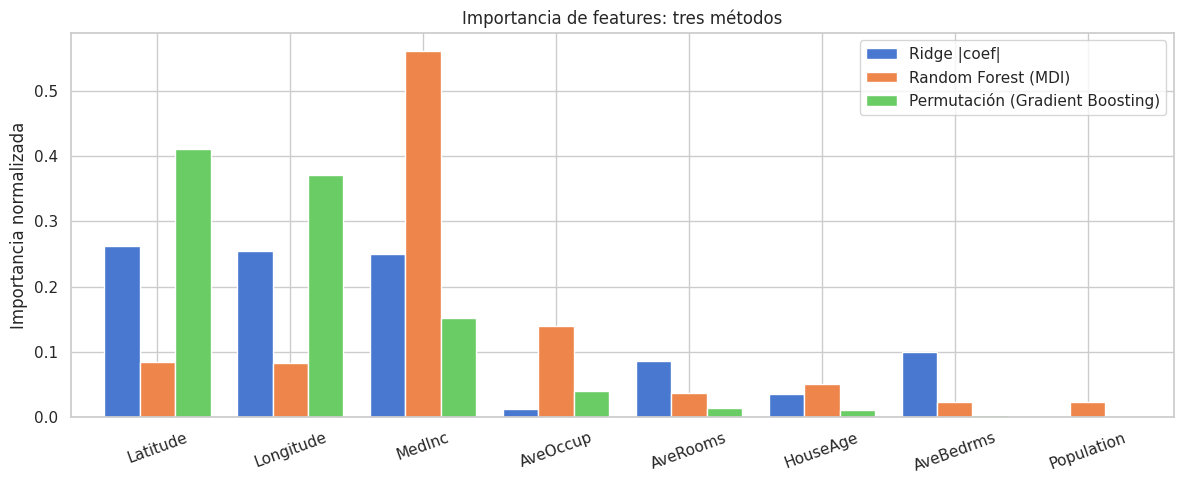

Correlación de rangos (Spearman) entre métodos:
                                 Ridge |coef|  Random Forest (MDI)  Permutación (Gradient Boosting)
Ridge |coef|                             1.00                 0.33                             0.79
Random Forest (MDI)                      0.33                 1.00                             0.76
Permutación (Gradient Boosting)          0.79                 0.76                             1.00


In [31]:
# 3. Gráfico de barras agrupadas
ax = imp_df.sort_values('Permutación (Gradient Boosting)', ascending=False).plot.bar(figsize=(12, 5), width=0.8)
ax.set_ylabel('Importancia normalizada'); ax.set_title('Importancia de features: tres métodos'); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()
print('Correlación de rangos (Spearman) entre métodos:')
print(imp_df.corr(method='spearman').round(2).to_string())

In [32]:
# 4c. ¿Se pueden eliminar features de baja importancia sin perder rendimiento? (se reentrena un Gradient Boosting)
orden = imp_df.mean(axis=1).sort_values(ascending=False).index.tolist()       # consenso de los tres métodos
filas = []
for k in [8, 7, 6, 5, 4, 3]:
    cols = orden[:k]
    m = GradientBoostingRegressor(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42).fit(Xi_tr[cols], yi_tr)
    filas.append({'features usadas': k, 'se eliminan': ', '.join(orden[k:]) or '-', 'R² test': m.score(Xi_te[cols], yi_te), 'RMSE': rmse(yi_te, m.predict(Xi_te[cols]))})
display(pd.DataFrame(filas).set_index('features usadas').round(4))

,se eliminan,R² test,RMSE
features usadas,,,
8,-,0.8180,0.4884
7,Population,0.8197,0.4861
6,"HouseAge, Population",0.8111,0.4976
5,"AveBedrms, HouseAge, Population",0.8158,0.4912
4,"AveRooms, AveBedrms, HouseAge, Population",0.8096,0.4995
3,"AveOccup, AveRooms, AveBedrms, HouseAge, Popul...",0.8020,0.5094


#### Respuesta
R² en test: Ridge 0.576 · Random Forest 0.791 · Gradient Boosting 0.818.

| Importancia normalizada | Ridge \|coef\| | RF (MDI) | Permutación (GB) |
|---|---|---|---|
| MedInc | 0.250 | **0.561** | 0.152 |
| Latitude | **0.262** | 0.084 | **0.411** |
| Longitude | 0.254 | 0.083 | 0.371 |
| AveOccup | 0.012 | 0.139 | 0.039 |
| AveRooms | 0.086 | 0.037 | 0.013 |
| AveBedrms | 0.099 | 0.022 | 0.003 |
| HouseAge | 0.036 | 0.050 | 0.010 |
| Population | 0.001 | 0.023 | 0.001 |

Correlación de rangos (Spearman): Ridge–MDI = 0.33, Ridge–Permutación = 0.79, MDI–Permutación = 0.76.

**¿Coinciden los 3 métodos?** Parcialmente. Coinciden en que `MedInc`, `Latitude` y `Longitude` son las variables clave y en que `Population` es la menos relevante; **discrepan en el orden y en la magnitud**: MDI concentra el 56 % en `MedInc` (y da peso a `AveOccup`), mientras que la permutación atribuye ≈ 78 % a la ubicación (latitud + longitud).

**¿Cuál es más confiable?** La **importancia por permutación** (sobre el conjunto de test): es agnóstica del modelo, mide cuánto empeora realmente el rendimiento al romper una variable y no está sesgada hacia variables continuas, a diferencia del MDI del Random Forest (calculado sobre train y que sobreestima variables con muchos cortes posibles). Los coeficientes de Ridge solo miden efectos lineales y subestiman el efecto no lineal de la ubicación (por eso Ridge rinde mucho peor). Salvedad: con features correlacionadas (latitud y longitud), la permutación individual puede repartir mal la importancia.

**¿Se pueden eliminar features de baja importancia?** Sí. Gradient Boosting reentrenado:

| Features usadas | Se eliminan | R² test | RMSE |
|---|---|---|---|
| 8 | — | 0.8180 | 0.4884 |
| 7 | Population | **0.8197** | 0.4861 |
| 6 | + HouseAge | 0.8111 | 0.4976 |
| 5 | + AveBedrms | 0.8158 | 0.4912 |
| 4 | + AveRooms | 0.8096 | 0.4995 |
| 3 (MedInc, Latitude, Longitude) | + AveOccup | 0.8020 | 0.5094 |

Quitar `Population` incluso mejora ligeramente; con 4 variables se pierde solo ≈ 0.8 puntos de R², y con las 3 principales ≈ 1.6 puntos. Un modelo mucho más simple conserva casi todo el rendimiento.

### Ejercicio 4.2 — Predicción con datos reales: Ames Housing
**Dataset:** Ames Housing (descargar desde Kaggle o usar `from sklearn.datasets import fetch_openml; fetch_openml(name='house_prices', as_frame=True)`)

**Tareas:**
1. **Exploración:** Estadísticas, distribuciones, correlaciones, valores faltantes
2. **Preprocesamiento:**
   - Manejar valores faltantes (imputación por mediana o moda según tipo)
   - Codificar variables categóricas (si las hay) con OneHotEncoder
   - Estandarizar features numéricas
3. **Modelado:** Entrenar al menos 4 modelos dentro de pipelines
4. **Evaluación:** Cross-validation (RMSE), gráficos de predicción vs real
5. **Tuning:** GridSearchCV para el mejor modelo
6. **Selección:** Justificar la elección del modelo final con métricas
7. **Interpretación:** ¿Qué features son más importantes para predecir el precio?

**Restricción:** Todo el flujo debe usar pipelines para evitar data leakage.

**Entregable:** Notebook completo tipo proyecto, con narrativa explicando cada decisión.

#### Solución

In [33]:
# Carga: OpenML (como sugiere el enunciado); si no hay acceso, copia del mismo archivo (Kaggle train.csv, 1460 viviendas)
URL_AMES = 'https://raw.githubusercontent.com/djeada/kaggle-house-prices/main/data/train.csv'
try:
    from sklearn.datasets import fetch_openml
    ames = fetch_openml(name='house_prices', as_frame=True, parser='auto')
    X_am, y_am = ames.data.copy(), ames.target.astype(float)
    fuente_am = 'OpenML (house_prices)'
except Exception:
    _df = pd.read_csv(URL_AMES)
    y_am = _df['SalePrice'].astype(float); X_am = _df.drop(columns=['SalePrice'])
    fuente_am = 'copia GitHub (Kaggle train.csv)'
X_am = X_am.drop(columns=[c for c in ['Id'] if c in X_am.columns])
from pandas.api.types import is_numeric_dtype
cat_am = [c for c in X_am.columns if not is_numeric_dtype(X_am[c])]          # texto / categorías
num_am = [c for c in X_am.columns if c not in cat_am]
X_am[cat_am] = X_am[cat_am].astype(object).where(X_am[cat_am].notna(), np.nan)
print('Fuente:', fuente_am, '| viviendas:', X_am.shape[0], '| variables:', X_am.shape[1], '(%d numéricas, %d categóricas)' % (len(num_am), len(cat_am)))

Fuente: copia GitHub (Kaggle train.csv) | viviendas: 1460 | variables: 79 (36 numéricas, 43 categóricas)


Estadísticas del precio (SalePrice):
count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Asimetría: 1.88  -> se aplicará log al target

Columnas con valores faltantes: 19 (las 10 con más faltantes)
PoolQC          99.5 %
MiscFeature     96.3 %
Alley           93.8 %
Fence           80.8 %
MasVnrType      59.7 %
FireplaceQu     47.3 %
LotFrontage     17.7 %
GarageQual       5.5 %
GarageFinish     5.5 %
GarageType       5.5 %


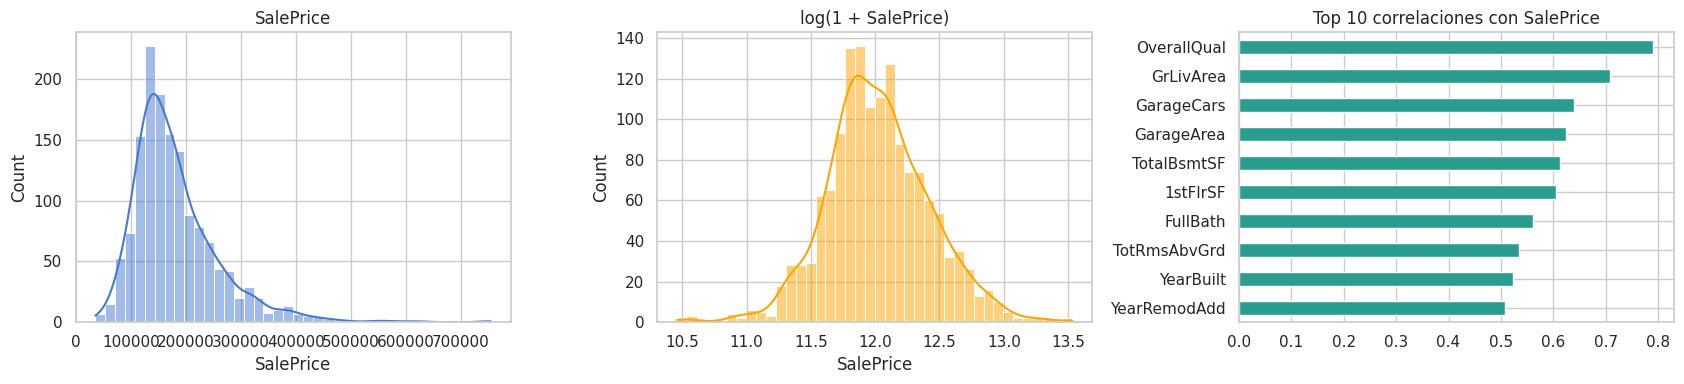

In [34]:
# 1. EXPLORACIÓN
print('Estadísticas del precio (SalePrice):'); print(y_am.describe().round(0).to_string())
print('Asimetría: %.2f  -> se aplicará log al target' % y_am.skew())
falt = X_am.isna().mean().sort_values(ascending=False); falt = falt[falt > 0]
print('\nColumnas con valores faltantes: %d (las 10 con más faltantes)' % len(falt))
print((falt.head(10) * 100).round(1).astype(str).add(' %').to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(y_am, kde=True, ax=axes[0], bins=40); axes[0].set_title('SalePrice')
sns.histplot(np.log1p(y_am), kde=True, ax=axes[1], bins=40, color='orange'); axes[1].set_title('log(1 + SalePrice)')
cor = pd.concat([X_am[num_am], y_am.rename('SalePrice')], axis=1).corr()['SalePrice'].drop('SalePrice').sort_values(key=np.abs, ascending=False).head(10)
cor.sort_values().plot.barh(ax=axes[2], color='#2a9d8f'); axes[2].set_title('Top 10 correlaciones con SalePrice')
plt.tight_layout(); plt.show()

In [35]:
# 2. PREPROCESAMIENTO dentro de un pipeline (sin fuga de datos)
#    - numéricas: mediana + estandarización
#    - categóricas: en Ames, NaN suele significar "no tiene" (sin sótano, sin garaje...) -> categoría 'Ninguno'; luego One-Hot
prep_am = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_am),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Ninguno')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_am),
])
def con_log(modelo):
    # el modelo se entrena sobre log(precio) y las predicciones se devuelven en dólares
    return TransformedTargetRegressor(regressor=Pipeline([('prep', prep_am), ('m', modelo)]), func=np.log1p, inverse_func=np.expm1)

Xam_tr, Xam_te, yam_tr, yam_te = train_test_split(X_am, y_am, test_size=0.2, random_state=42)
modelos_am = {
    'Ridge (α=10)': con_log(Ridge(alpha=10)),
    'Lasso (α=0.001)': con_log(Lasso(alpha=0.001, max_iter=20000)),
    'Random Forest': con_log(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)),
    'Gradient Boosting': con_log(GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)),
}
print('Train:', Xam_tr.shape, '| Test:', Xam_te.shape)

Train: (1168, 79) | Test: (292, 79)


Ridge (α=10)         RMSE CV =     41356 ±  26436 USD   (0 s)


Lasso (α=0.001)      RMSE CV =     44453 ±  32824 USD   (0 s)


Random Forest        RMSE CV =     30943 ±   4244 USD   (61 s)


Gradient Boosting    RMSE CV =     27464 ±   5873 USD   (9 s)


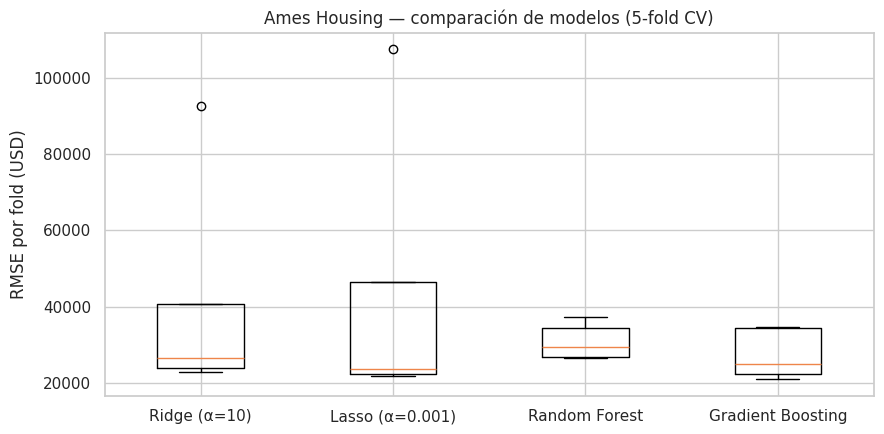

In [36]:
# 3-4. MODELADO y EVALUACIÓN con validación cruzada (RMSE en dólares)
cv_am = KFold(5, shuffle=True, random_state=42)
res_am = {}
for nombre, mod in modelos_am.items():
    t0 = time.time()
    s = cross_val_score(mod, Xam_tr, yam_tr, cv=cv_am, scoring='neg_root_mean_squared_error')
    res_am[nombre] = -s
    print('%-20s RMSE CV = %9.0f ± %6.0f USD   (%.0f s)' % (nombre, -s.mean(), s.std(), time.time() - t0))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(list(res_am.values()), tick_labels=list(res_am.keys())); ax.set_ylabel('RMSE por fold (USD)')
ax.set_title('Ames Housing — comparación de modelos (5-fold CV)'); plt.tight_layout(); plt.show()

In [37]:
# 5. TUNING con GridSearchCV sobre el mejor modelo
mejor_am = min(res_am, key=lambda k: res_am[k].mean())
print('Mejor modelo base:', mejor_am)
grillas_am = {
    'Ridge (α=10)': {'regressor__m__alpha': [1, 3, 10, 30, 100]},
    'Lasso (α=0.001)': {'regressor__m__alpha': [0.0003, 0.001, 0.003, 0.01]},
    'Random Forest': {'regressor__m__max_features': ['sqrt', 0.3, 0.5], 'regressor__m__min_samples_leaf': [1, 2, 4]},
    'Gradient Boosting': {'regressor__m__n_estimators': [300, 600], 'regressor__m__learning_rate': [0.03, 0.05],
                          'regressor__m__max_depth': [2, 3, 4]},
}
gs_am = GridSearchCV(modelos_am[mejor_am], grillas_am[mejor_am], cv=cv_am, scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_am.fit(Xam_tr, yam_tr)
print('Mejores hiperparámetros:', gs_am.best_params_)
print('RMSE CV tras el tuning: %.0f USD (antes: %.0f USD)' % (-gs_am.best_score_, res_am[mejor_am].mean()))

Mejor modelo base: Gradient Boosting


Mejores hiperparámetros: {'regressor__m__learning_rate': 0.05, 'regressor__m__max_depth': 3, 'regressor__m__n_estimators': 600}
RMSE CV tras el tuning: 26942 USD (antes: 27464 USD)


TEST -> RMSE = 27507 USD | MAE = 15909 USD | R² = 0.9014
RMSE en escala logarítmica (métrica de la competencia Kaggle): 0.1325


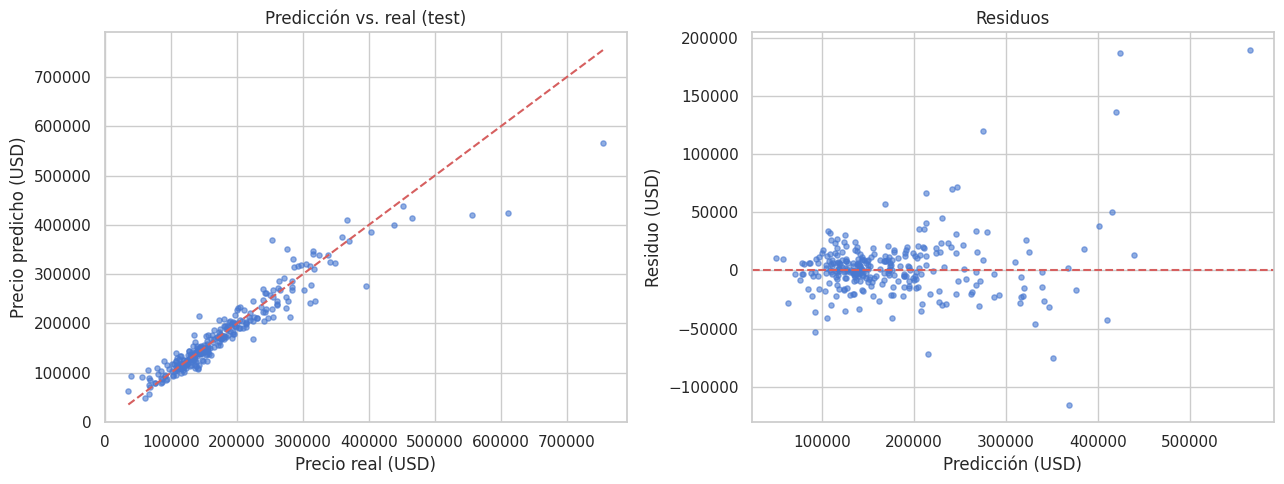

In [38]:
# 6. SELECCIÓN FINAL: evaluación en test del modelo optimizado
final_am = gs_am.best_estimator_
p_am = final_am.predict(Xam_te)
m_am = metricas(yam_te, p_am)
print('TEST -> RMSE = %.0f USD | MAE = %.0f USD | R² = %.4f' % (m_am['RMSE'], m_am['MAE'], m_am['R2']))
print('RMSE en escala logarítmica (métrica de la competencia Kaggle): %.4f' % rmse(np.log(yam_te), np.log(p_am)))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(yam_te, p_am, s=14, alpha=0.6); lim = [yam_te.min(), yam_te.max()]; axes[0].plot(lim, lim, 'r--')
axes[0].set_xlabel('Precio real (USD)'); axes[0].set_ylabel('Precio predicho (USD)'); axes[0].set_title('Predicción vs. real (test)')
axes[1].scatter(p_am, yam_te - p_am, s=14, alpha=0.6); axes[1].axhline(0, color='r', ls='--')
axes[1].set_xlabel('Predicción (USD)'); axes[1].set_ylabel('Residuo (USD)'); axes[1].set_title('Residuos')
plt.tight_layout(); plt.show()

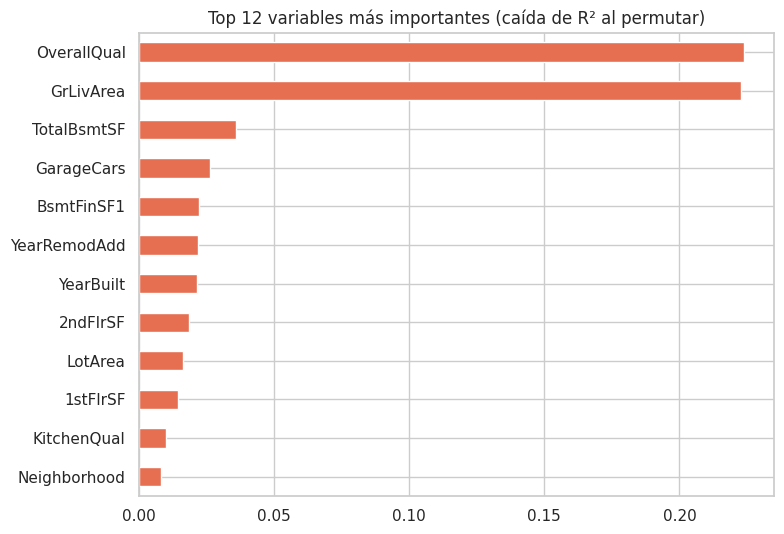

OverallQual     0.2238
GrLivArea       0.2229
TotalBsmtSF     0.0358
GarageCars      0.0262
BsmtFinSF1      0.0221
YearRemodAdd    0.0217
YearBuilt       0.0215
2ndFlrSF        0.0186
LotArea         0.0162
1stFlrSF        0.0145


In [39]:
# 7. INTERPRETACIÓN: importancia por permutación sobre las columnas ORIGINALES (el pipeline hace el preprocesamiento)
pi_am = permutation_importance(final_am, Xam_te, yam_te, n_repeats=5, random_state=42, scoring='r2')
imp_am = pd.Series(pi_am.importances_mean, index=Xam_te.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
imp_am.head(12).sort_values().plot.barh(ax=ax, color='#e76f51'); ax.set_title('Top 12 variables más importantes (caída de R² al permutar)')
plt.tight_layout(); plt.show()
print(imp_am.head(10).round(4).to_string())

#### Narrativa y decisiones
1. **Exploración:** 1 460 viviendas y 79 variables (36 numéricas, 43 categóricas). El precio tiene media 180 921 y mediana 163 000 USD, con asimetría 1.88 → se entrena sobre **log(precio)** y se devuelven las predicciones en dólares. Hay 19 columnas con faltantes: `PoolQC` (99.5 %), `MiscFeature` (96.3 %), `Alley` (93.8 %), `Fence` (80.8 %), `MasVnrType`, `FireplaceQu`… En Ames un `NaN` significa normalmente **"no tiene"** (sin piscina, sin callejón…), así que en las categóricas se imputa con la categoría `Ninguno` (no con la moda); las numéricas (p. ej. `LotFrontage`, 17.7 %) se imputan con la mediana.
2. **Preprocesamiento (todo en pipelines, sin fuga de datos):** `ColumnTransformer` con mediana + estandarización para numéricas y `Ninguno` + One-Hot para categóricas; el imputador y el escalador se ajustan solo con los datos de cada fold de entrenamiento.
3. **Modelos y validación cruzada (RMSE, 5-fold):**

| Modelo | RMSE CV (USD) |
|---|---|
| Ridge (α=10) | 41 356 ± 26 436 |
| Lasso (α=0.001) | 44 453 ± 32 824 |
| Random Forest | 30 943 ± 4 244 |
| **Gradient Boosting** | **27 464 ± 5 873** |

   Ridge y Lasso, además de peores, son muy **inestables** (desviación de 26–33 mil): en algún fold una vivienda atípica produce una predicción extrema que el `exp` del log amplifica.
4. **Tuning (`GridSearchCV` sobre Gradient Boosting):** mejor combinación `learning_rate = 0.05`, `max_depth = 3`, `n_estimators = 600` → RMSE CV 26 942 USD (antes 27 464).
5. **Selección y evaluación final (test de 292 viviendas):** **RMSE = 27 507 USD, MAE = 15 909 USD, R² = 0.901**, RMSE en escala logarítmica = 0.1325. Se elige Gradient Boosting por tener el mejor error en CV y en test y por ser estable entre folds; los modelos lineales regularizados son más simples pero claramente peores e inestables.
6. **Interpretación (importancia por permutación, caída de R²):** `OverallQual` (0.224) y `GrLivArea` (0.223) dominan con diferencia; después `TotalBsmtSF` (0.036), `GarageCars` (0.026), `BsmtFinSF1` (0.022), `YearRemodAdd` (0.022) y `YearBuilt` (0.022). Es decir, el precio lo determinan sobre todo la **calidad general de materiales y acabados** y la **superficie habitable**, seguidas de sótano, cochera y antigüedad/remodelación.
7. **Limitación:** el test es pequeño (292 casas), por lo que las cifras finales y las importancias tienen un margen de error apreciable.